In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
import string
import re    #for regex
from nltk.corpus import stopwords
#import spacy
from nltk import pos_tag
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB , BernoulliNB , MultinomialNB 
from sklearn.metrics import classification_report , r2_score,f1_score
from  sklearn.svm import SVC,SVR
from sklearn import model_selection, preprocessing, linear_model, naive_bayes, metrics, svm, decomposition, ensemble
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split , GridSearchCV
import textblob
import xgboost

from textblob import TextBlob
from nltk.stem import PorterStemmer, SnowballStemmer

In [2]:
# Data Importing

In [3]:
review = pd.read_excel("D:\\Analytic_X_lab\\Machine_learning_project\\15. Capstone Case Study - NLP- Woman Clothing E-Commerce Platform\\Womens Clothing Reviews Data.xlsx")

# <center> DATA UNDERSTANDING </center>

In [4]:
review.head()

,Product ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer Age,Review Title,Review Text,Rating,Recommend Flag
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0
3,1049,General Petite,Bottoms,Pants,Chennai,Web,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,847,General,Tops,Blouses,Bangalore,Web,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1


In [5]:
print("Observation in Review dataframe is  : ", review.shape[0])
print("Observation in Review dataframe is  : ", review.shape[1])

Observation in Review dataframe is  :  23486
Observation in Review dataframe is  :  11


In [6]:
# checking Columns name
review.columns

Index(['Product ID', 'Category', 'Subcategory1', 'SubCategory2', 'Location',
       'Channel', 'Customer Age', 'Review Title', 'Review Text', 'Rating',
       'Recommend Flag'],
      dtype='object')

In [7]:

# checking first five row
review.head()

,Product ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer Age,Review Title,Review Text,Rating,Recommend Flag
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0
3,1049,General Petite,Bottoms,Pants,Chennai,Web,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,847,General,Tops,Blouses,Bangalore,Web,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1


In [8]:
# checking last five row
review.tail()

,Product ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer Age,Review Title,Review Text,Rating,Recommend Flag
23481,1104,General Petite,Dresses,Dresses,Gurgaon,Mobile,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1
23482,862,General Petite,Tops,Knits,Gurgaon,Web,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1
23483,1104,General Petite,Dresses,Dresses,Gurgaon,Web,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0
23484,1084,General,Dresses,Dresses,Gurgaon,Web,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1
23485,1104,General Petite,Dresses,Dresses,Chennai,Mobile,52,Please make more like this one!,This dress in a lovely platinum is feminine an...,5,1


In [9]:
# checking datatype 
review.dtypes

Product ID         int64
Category          object
Subcategory1      object
SubCategory2      object
Location          object
Channel           object
Customer Age       int64
Review Title      object
Review Text       object
Rating             int64
Recommend Flag     int64
dtype: object

In [10]:
# checking data date with record 
review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Product ID      23486 non-null  int64 
 1   Category        23472 non-null  object
 2   Subcategory1    23472 non-null  object
 3   SubCategory2    23472 non-null  object
 4   Location        23486 non-null  object
 5   Channel         23486 non-null  object
 6   Customer Age    23486 non-null  int64 
 7   Review Title    19676 non-null  object
 8   Review Text     22641 non-null  object
 9   Rating          23486 non-null  int64 
 10  Recommend Flag  23486 non-null  int64 
dtypes: int64(4), object(7)
memory usage: 2.0+ MB


In [11]:
# checking Missing value
review.isna().sum()

Product ID           0
Category            14
Subcategory1        14
SubCategory2        14
Location             0
Channel              0
Customer Age         0
Review Title      3810
Review Text        845
Rating               0
Recommend Flag       0
dtype: int64

In [12]:
# checking Missing value in Percentage
review.isna().sum() / review.shape[0] * 100

Product ID         0.000000
Category           0.059610
Subcategory1       0.059610
SubCategory2       0.059610
Location           0.000000
Channel            0.000000
Customer Age       0.000000
Review Title      16.222430
Review Text        3.597888
Rating             0.000000
Recommend Flag     0.000000
dtype: float64

In [13]:
# checking Duplicate Record
review.duplicated().sum()

np.int64(3)

In [28]:
# checking Unique Vale
#print("Category :" , review["Category"].unique())
#print("Rating  :" , review["Rating"].unique())
#print("Channel  :" , review["Channel"].unique())
#print(" Recommend Flag:" , review["Recommend Flag"].unique())


x = ["Category","Rating","Channel","Recommend Flag"]
for i in x:
    print()
    print(f'Columns name:{i}\n{review[i].unique()}')




Columns name:Category
['Initmates' 'General' 'General Petite' nan]

Columns name:Rating
[4 5 3 2 1]

Columns name:Channel
['Mobile' 'Web']

Columns name:Recommend Flag
[1 0]


In [30]:
# checking Frequency Count
x = ["Category","Rating","Channel","Recommend Flag"]
for i in x:
    print()
    print(f'Columns name:{i}\n{review[i].value_counts()}')




Columns name:Category
Category
General           13850
General Petite     8120
Initmates          1502
Name: count, dtype: int64

Columns name:Rating
Rating
5    13131
4     5077
3     2871
2     1565
1      842
Name: count, dtype: int64

Columns name:Channel
Channel
Web       13583
Mobile     9903
Name: count, dtype: int64

Columns name:Recommend Flag
Recommend Flag
1    19314
0     4172
Name: count, dtype: int64


In [59]:
# Statistical Summary
review.describe().T

,count,mean,std,min,25%,50%,75%,max
Product ID,23486.0,918.118709,203.298980,0.0,861.0,936.0,1078.0,1205.0
Customer Age,23486.0,43.198544,12.279544,18.0,34.0,41.0,52.0,99.0
Rating,23486.0,4.196032,1.110031,1.0,4.0,5.0,5.0,5.0
Recommend Flag,23486.0,0.822362,0.382216,0.0,1.0,1.0,1.0,1.0


# <center>DATA CLEANING</center>

In [60]:
# Cleaning the column name
review.columns = review.columns.str.replace(" ","_")

In [61]:
# Handling missing value 
review["Category"] = review["Category"].fillna("Unknown")
review["Subcategory1"] = review["Subcategory1"].fillna("Unknown")
review["SubCategory2"] = review["SubCategory2"].fillna("Unknown")
review["Review_Title"] = review["Review_Title"].fillna("")

In [62]:
#Review Text is the primary NLP feature in my project. Since 845 records do not contain any review text, 
#they cannot contribute to text preprocessing or sentiment analysis.
#Therefore, I removed only those records with missing Review Text instead of imputing artificial text.
review = review.dropna(subset=["Review_Text"])

In [63]:
review.isna().sum()

Product_ID        0
Category          0
Subcategory1      0
SubCategory2      0
Location          0
Channel           0
Customer_Age      0
Review_Title      0
Review_Text       0
Rating            0
Recommend_Flag    0
dtype: int64

In [64]:
review.Rating.value_counts() / review.shape[0]

Rating
5    0.553862
4    0.216775
3    0.124685
2    0.068416
1    0.036262
Name: count, dtype: float64

In [65]:
review.shape

(22641, 11)

In [66]:
# Removing Duplicate Record
review.drop_duplicates(inplace=True)
review.duplicated().sum()

np.int64(0)

 # <center>EDA — Exploratory Data Analysis </center>

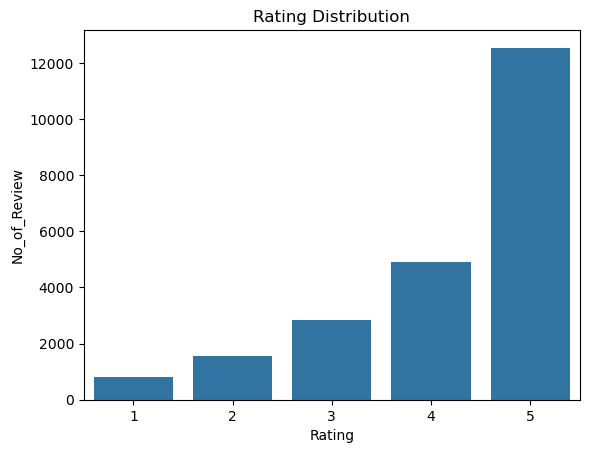

In [67]:
# Rating Distribution 
RD=review["Rating"].value_counts().reset_index()

sns.barplot(data = RD , x = "Rating" , y = "count")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("No_of_Review")
plt.show()

#The rating distribution shows that 5-star ratings are the most frequent,
#indicating that a large proportion of customers gave highly positive ratings.

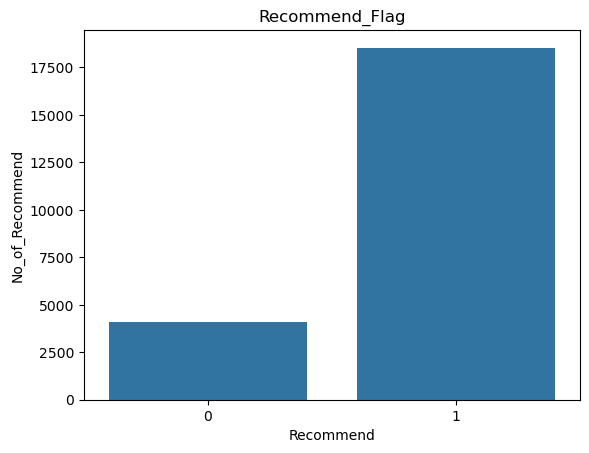

In [68]:
# Recommended Flag 
RF=review["Recommend_Flag"].value_counts().reset_index()

sns.barplot(data = RF , x = "Recommend_Flag" , y = "count")
plt.title("Recommend_Flag")
plt.xlabel("Recommend")
plt.ylabel("No_of_Recommend")
plt.show()


#Most customers recommend the products, as the graph shows that Recommend_Flag = 1 has the highest count, 
#with approximately 17,500 reviews. 
#This indicates an overall positive customer response toward the products

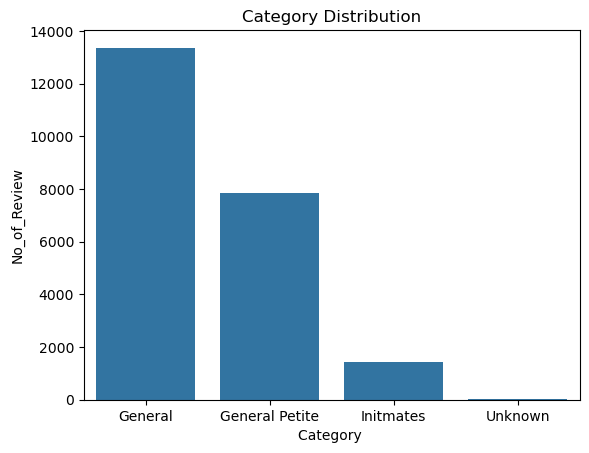

In [69]:
# Category Analysis
RC=review["Category"].value_counts().reset_index()

sns.barplot(data = RC , x = "Category" , y = "count")
plt.title("Category Distribution")
plt.xlabel("Category ")
plt.ylabel("No_of_Review")
plt.show()

#The General category has the highest number of reviews, with approximately 13,665 reviews. This indicates that customers
#provided more reviews for products in the General category compared to other categories.

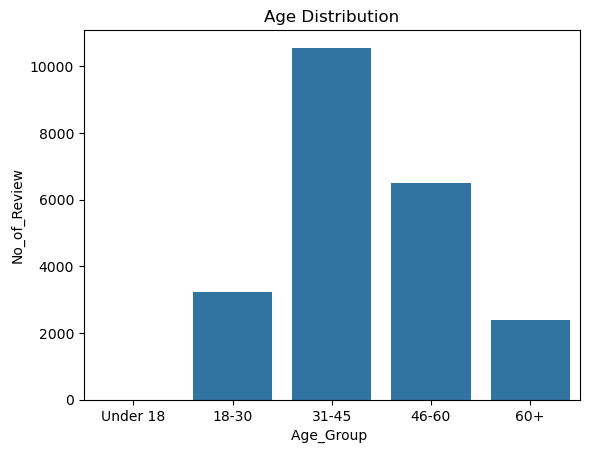

In [70]:
# Age Analysis
bins = [0, 18, 30, 45, 60, 100]
labels = ["Under 18", "18-30", "31-45", "46-60", "60+"]

review["Age_Group"] = pd.cut(
    review["Customer_Age"],
    bins=bins,
    labels=labels
)

RA=review["Age_Group"].value_counts().reset_index()

sns.barplot(data = RA , x = "Age_Group" , y = "count")
plt.title("Age Distribution")
plt.xlabel("Age_Group ")
plt.ylabel("No_of_Review")
plt.show()

#The 31–35 age group has the highest number of reviews compared to other age groups. 
#This indicates that customers in this age group are more strongly represented in the review dataset.

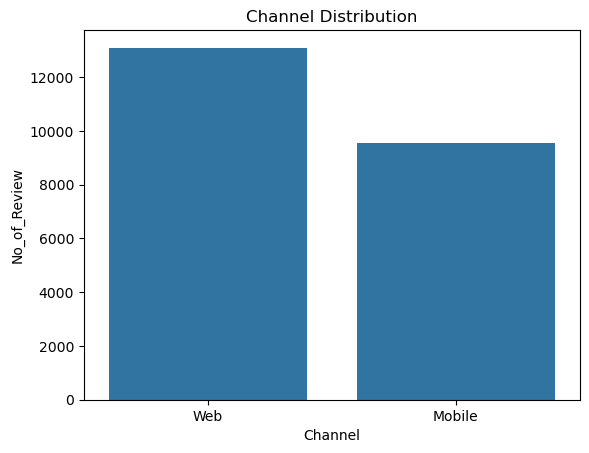

In [71]:
# Channel Analysis


RCH=review["Channel"].value_counts().reset_index()

sns.barplot(data = RCH , x = "Channel" , y = "count")
plt.title("Channel Distribution")
plt.xlabel("Channel")
plt.ylabel("No_of_Review")
plt.show()
#The Web channel has the highest number of reviews compared to the Mobile channel,
#indicating that customers provided more reviews through the Web channel.

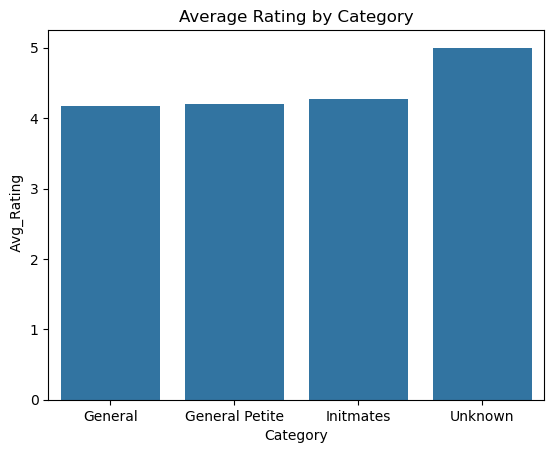

In [72]:
# Category vs Rating
C=review.groupby("Category")["Rating"].mean().reset_index()


sns.barplot(data = C , x = "Category" , y = "Rating")
plt.title("Average Rating by Category")
plt.xlabel("Category")
plt.ylabel(" Avg_Rating")
plt.show()
#The Unknow category has the highest average rating compared to other categories, indicating
#that customers gave relatively higher ratings to products in this category.

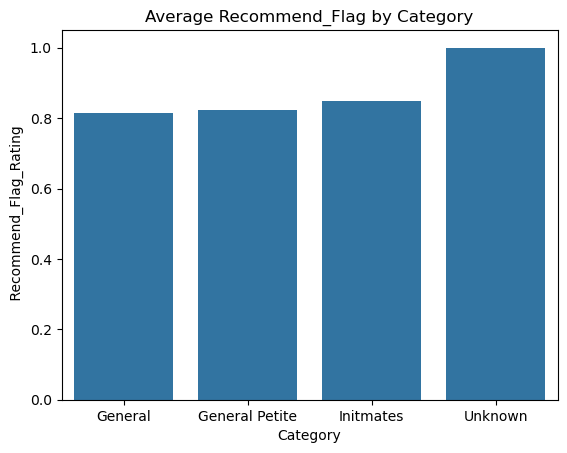

In [73]:
# Category vs Recommend
CR=review.groupby("Category")["Recommend_Flag"].mean().reset_index()
sns.barplot(data = CR , x = "Category" , y = "Recommend_Flag")
plt.title("Average Recommend_Flag by Category")
plt.xlabel("Category")
plt.ylabel(" Recommend_Flag_Rating")
plt.show()

#The Unknown category has the highest average recommendation rate compared to other categories,
#indicating that a higher proportion of customers recommend products from this category.

C:\Users\Asus\AppData\Local\Temp\ipykernel_26144\3528019686.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  A=review.groupby("Age_Group")["Rating"].mean().reset_index().round(2).sort_values("Rating",ascending = False)


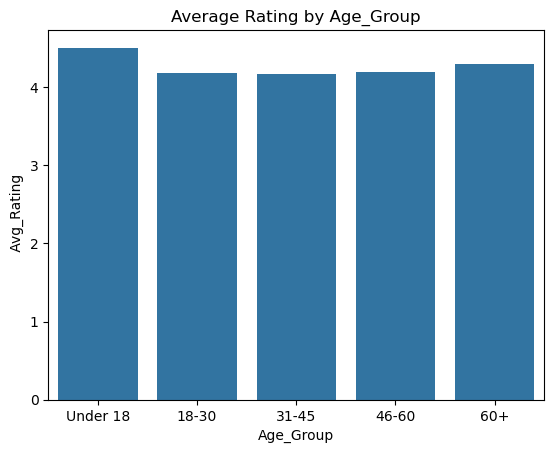

In [74]:
# Age vs Rating
A=review.groupby("Age_Group")["Rating"].mean().reset_index().round(2).sort_values("Rating",ascending = False)
sns.barplot(data = A , x = "Age_Group" , y = "Rating")
plt.title("Average Rating by Age_Group")
plt.xlabel("Age_Group")
plt.ylabel(" Avg_Rating")
plt.show()

#The Under 18 age group has the highest average rating compared to other age groups,
#indicating that customers in this age group gave relatively higher ratings to the products

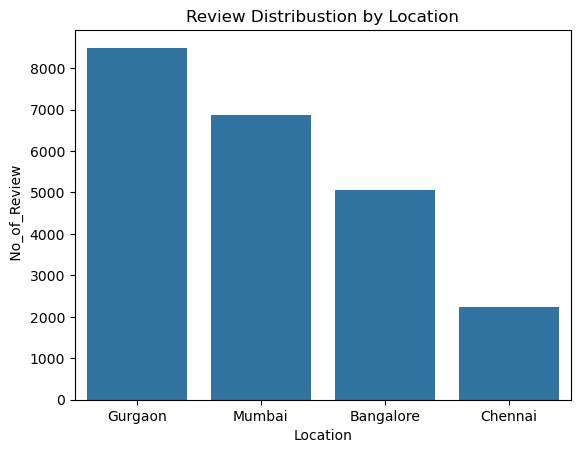

In [75]:
# Location Analysis
L = review.Location.value_counts().reset_index()
sns.barplot(data = L , x = "Location" , y = "count")
plt.title("Review Distribustion by Location")
plt.xlabel("Location")
plt.ylabel(" No_of_Review")
plt.show()
#The Gurgaon location has the highest number of reviews compared to other locations,
#indicating that customers from this location are more strongly represented in the review dataset.

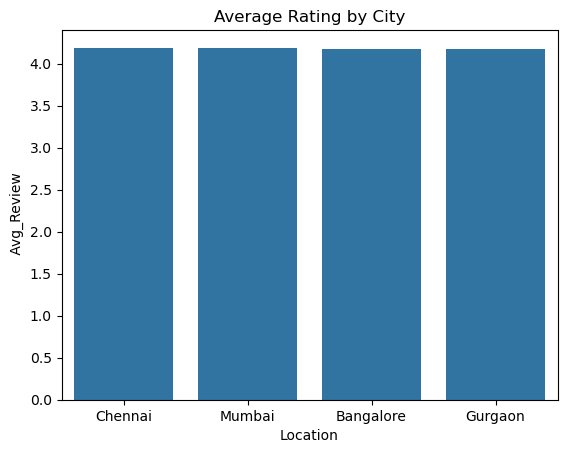

In [76]:
LO=review.groupby("Location")["Rating"].mean().reset_index().round(2).sort_values("Rating",ascending = False)
sns.barplot(data = LO , x = "Location" , y = "Rating")
plt.title("Average Rating by City")
plt.xlabel("Location")
plt.ylabel(" Avg_Review")
plt.show()
#The Chennai  and Mumbai location has the highest average rating compared to other locations,
# indicating that customers from this location gave relatively higher ratings to the products.

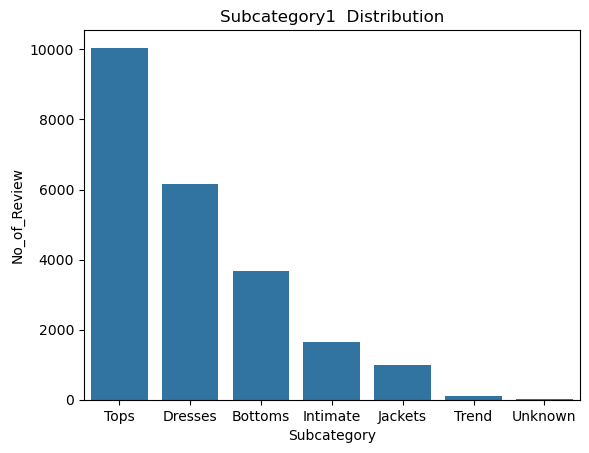

In [77]:
Sub1=review["Subcategory1"].value_counts().reset_index()

sns.barplot(data = Sub1 , x = "Subcategory1" , y = "count")
plt.title("Subcategory1  Distribution")
plt.xlabel("Subcategory")
plt.ylabel("No_of_Review")
plt.show()
#The Tops subcategory1 has the highest number of reviews compared to other subcategories, 
#indicating that products within this subcategory are more strongly represented in the review dataset.

In [78]:
review.columns

Index(['Product_ID', 'Category', 'Subcategory1', 'SubCategory2', 'Location',
       'Channel', 'Customer_Age', 'Review_Title', 'Review_Text', 'Rating',
       'Recommend_Flag', 'Age_Group'],
      dtype='object')

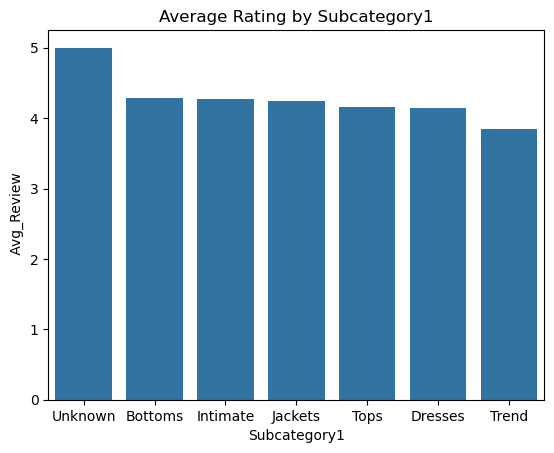

In [79]:
Su=review.groupby("Subcategory1")["Rating"].mean().reset_index().round(2).sort_values("Rating",ascending = False)
sns.barplot(data = Su , x = "Subcategory1" , y = "Rating")
plt.title("Average Rating by Subcategory1")
plt.xlabel("Subcategory1")
plt.ylabel(" Avg_Review")
plt.show()
#The Unknown subcategory has the highest average rating compared to other subcategories,
#indicating that customers gave relatively higher ratings to products in this subcategory

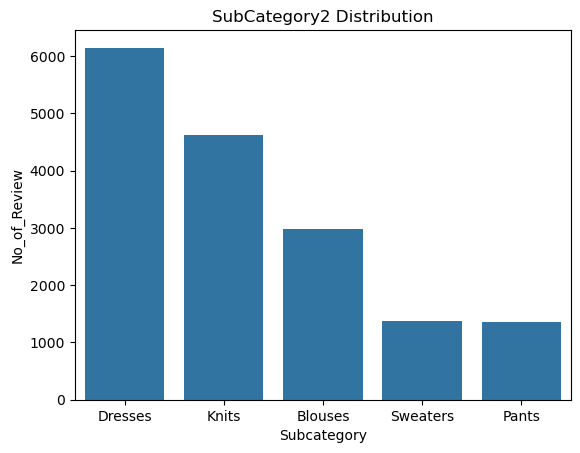

In [80]:
Sub2=review["SubCategory2"].value_counts().reset_index().sort_values("count",ascending=False).head(5)

sns.barplot(data = Sub2 , x = "SubCategory2" , y = "count")
plt.title("SubCategory2 Distribution")
plt.xlabel("Subcategory")
plt.ylabel("No_of_Review")
plt.show()
#The Dresses subcategory2 has the highest number of reviews compared to other subcategories, 
#indicating that products within this subcategory are more strongly represented in the review dataset.

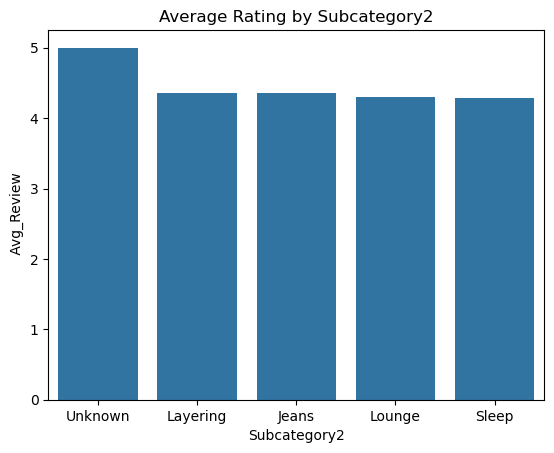

In [81]:
Su1=review.groupby("SubCategory2")["Rating"].mean().reset_index().round(2).sort_values("Rating",ascending = False).head(5)
sns.barplot(data = Su1 , x = "SubCategory2" , y = "Rating")
plt.title("Average Rating by Subcategory2")
plt.xlabel("Subcategory2")
plt.ylabel(" Avg_Review")
plt.show()
#The Unknown subcategory has the highest average rating compared to other subcategories,
#indicating that customers gave relatively higher ratings to products in this subcategory

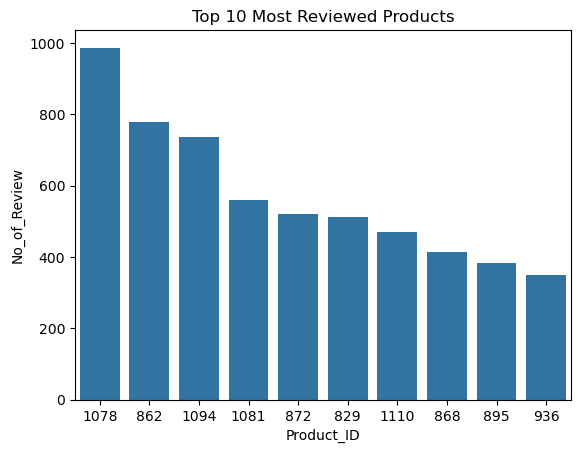

In [82]:
# Top 10 Product by Reviews
RP = review["Product_ID"].value_counts().reset_index().head(10)
RP["Product_ID"] = RP["Product_ID"].astype(str)

sns.barplot(data = RP , x = "Product_ID" , y = "count")
plt.title("Top 10 Most Reviewed Products")
plt.xlabel("Product_ID")
plt.ylabel("No_of_Review")
plt.show()

#

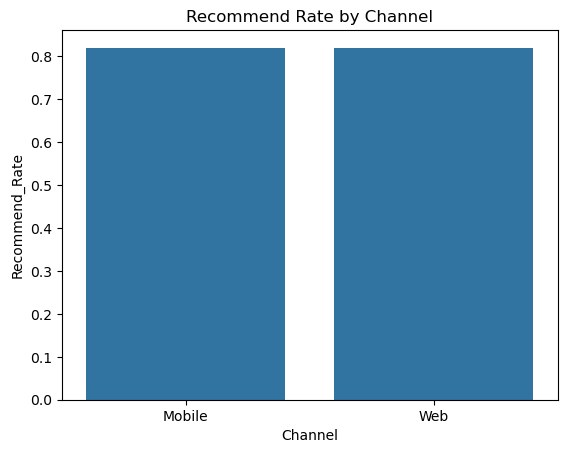

In [83]:
# Channel vs Recommend
CRF = review.groupby("Channel")["Recommend_Flag"].mean().reset_index().round(2)

sns.barplot(data = CRF , x = "Channel" , y = "Recommend_Flag")
plt.title("Recommend Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("Recommend_Rate")
plt.show()

#

# <center>TEXT MINING</center>

In [84]:
!pip install wordcloud
!pip install textblob

In [85]:
review.columns

Index(['Product_ID', 'Category', 'Subcategory1', 'SubCategory2', 'Location',
       'Channel', 'Customer_Age', 'Review_Title', 'Review_Text', 'Rating',
       'Recommend_Flag', 'Age_Group'],
      dtype='object')

In [86]:
review["text"] = review["Review_Title"].fillna("") + " " + review["Review_Text"].fillna("")

In [87]:
review["Sentiment"] = np.where(review.Rating >=4 , "Pos","Neg" )

In [88]:
review.Sentiment.value_counts() / review.shape[0] *100

Sentiment
Pos    77.063734
Neg    22.936266
Name: count, dtype: float64

In [89]:
# We need to clean the text

# lower case
# stop words
# special characters
# stemming, lemmatization
# tokinizer into number dataframe
# train and test
# algorithm
# predictions

In [90]:
#stopwords.words('english')

In [91]:
st = "I love python"
st.split()

['I', 'love', 'python']

In [92]:
stemmer = PorterStemmer()

In [93]:
stemmer.stem("stemming")

'stem'

In [94]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [95]:
# Step 3: Text cleaning

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()                              # lowercase
    text = re.sub(r'<.*?>', '', text)                # remove HTML tags
    text = re.sub(r'[^a-z\s]', '', text)             # remove punctuation/numbers
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words]  # remove stopwords
    tokens = [stemmer.stem(t) for t in tokens]       # stemming
    return ' '.join(tokens)

In [96]:
review["clean_Text"] = review.text.apply(clean_text)

In [97]:

#  TF-IDF vectorization

vectorizer = TfidfVectorizer(
    max_features=10000,      # top 10k tokens by TF-IDF score
    ngram_range=(1, 2),      # unigrams + bigrams
    min_df=2,                # ignore terms in fewer than 2 docs
    max_df= 0.95             # ignore terms in >95% of docs
)

In [98]:
X=vectorizer.fit_transform(review["clean_Text"])
y= review["Sentiment"].values

In [99]:
X.toarray

<bound method _cs_matrix.toarray of <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 854446 stored elements and shape (22641, 10000)>>

In [100]:
y

array(['Pos', 'Pos', 'Neg', ..., 'Neg', 'Neg', 'Pos'],
      shape=(22641,), dtype=object)

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.30,random_state= 123)

In [102]:
X_train.shape

(15848, 10000)

In [103]:
X_test.shape

(6793, 10000)

In [104]:
y_train.shape

(15848,)

In [105]:
y_test.shape

(6793,)

# <center>Logistic Regression </center>

In [106]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [107]:
print(classification_report(y_train,model.predict(X_train)))

              precision    recall  f1-score   support

         Neg       0.76      0.94      0.84      3678
         Pos       0.98      0.91      0.94     12170

    accuracy                           0.92     15848
   macro avg       0.87      0.93      0.89     15848
weighted avg       0.93      0.92      0.92     15848



In [108]:
print(classification_report(y_test,model.predict(X_test)))

              precision    recall  f1-score   support

         Neg       0.68      0.86      0.76      1515
         Pos       0.96      0.89      0.92      5278

    accuracy                           0.88      6793
   macro avg       0.82      0.87      0.84      6793
weighted avg       0.89      0.88      0.88      6793



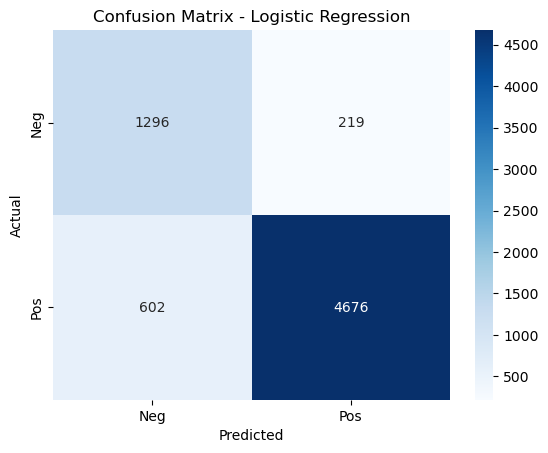

In [109]:
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=["Neg", "Pos"])

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# <center>Navie Bayes </center>

In [110]:
m = MultinomialNB()

In [111]:
m.fit(X_train,y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [112]:
print(classification_report(y_train,m.predict(X_train)))

              precision    recall  f1-score   support

         Neg       0.91      0.58      0.71      3678
         Pos       0.88      0.98      0.93     12170

    accuracy                           0.89     15848
   macro avg       0.90      0.78      0.82     15848
weighted avg       0.89      0.89      0.88     15848



In [113]:
print(classification_report(y_test,m.predict(X_test)))

              precision    recall  f1-score   support

         Neg       0.85      0.49      0.62      1515
         Pos       0.87      0.97      0.92      5278

    accuracy                           0.87      6793
   macro avg       0.86      0.73      0.77      6793
weighted avg       0.87      0.87      0.85      6793



In [114]:
param_grid = {
    "alpha": [0.01, 0.1, 0.5, 1.0, 2.0]
}

grid = GridSearchCV(
    MultinomialNB(),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
grid.fit(X_train,y_train)

C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan]
  warnings.warn(


,estimator,MultinomialNB()
,param_grid,"{'alpha': [0.01, 0.1, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.01


In [115]:
print(classification_report(y_train,grid.predict(X_train)))

              precision    recall  f1-score   support

         Neg       0.89      0.77      0.82      3678
         Pos       0.93      0.97      0.95     12170

    accuracy                           0.92     15848
   macro avg       0.91      0.87      0.89     15848
weighted avg       0.92      0.92      0.92     15848



In [116]:
print(classification_report(y_test,grid.predict(X_test)))

              precision    recall  f1-score   support

         Neg       0.82      0.60      0.69      1515
         Pos       0.89      0.96      0.93      5278

    accuracy                           0.88      6793
   macro avg       0.85      0.78      0.81      6793
weighted avg       0.88      0.88      0.87      6793



 # <center>Support Vector Machine</center>

In [117]:
#svm = SVC()
#svm.fit(X_train,y_train)

In [118]:
#print(classification_report(y_train,svm.predict(X_train)))

In [119]:
#print(classification_report(y_test,svm.predict(X_test)))

In [120]:
#params = {'C' : [0.02,0.04,0.08,0.50,0.83, 0.10 ],'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],'degree' : [2,3,4]}

In [121]:
#svc_gcv = GridSearchCV(SVC(class_weight="balanced"), param_grid= params, cv = 5, n_jobs=-1, verbose = True)

In [122]:
#svc_gcv.fit(X_train,y_train)

In [123]:
#print(classification_report(y_train,svc_gcv.predict(X_train)))

In [124]:
#print(classification_report(y_test,svc_gcv.predict(X_test)))

# <center>Random Forest Classifer </center>

In [125]:
RNN= RandomForestClassifier(random_state=123 ,class_weight="balanced",
    n_jobs=-1)

In [126]:
RNN.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [127]:
print(classification_report(y_train,RNN.predict(X_train)))

              precision    recall  f1-score   support

         Neg       1.00      1.00      1.00      3678
         Pos       1.00      1.00      1.00     12170

    accuracy                           1.00     15848
   macro avg       1.00      1.00      1.00     15848
weighted avg       1.00      1.00      1.00     15848



In [128]:
print(classification_report(y_test,RNN.predict(X_test)))

              precision    recall  f1-score   support

         Neg       0.84      0.52      0.64      1515
         Pos       0.88      0.97      0.92      5278

    accuracy                           0.87      6793
   macro avg       0.86      0.75      0.78      6793
weighted avg       0.87      0.87      0.86      6793



In [129]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)




C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


,estimator,RandomForestClassifier()
,param_grid,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [130]:
print(classification_report(y_train,grid_rf.predict(X_train)))

              precision    recall  f1-score   support

         Neg       1.00      1.00      1.00      3678
         Pos       1.00      1.00      1.00     12170

    accuracy                           1.00     15848
   macro avg       1.00      1.00      1.00     15848
weighted avg       1.00      1.00      1.00     15848



In [131]:
print(classification_report(y_test,grid_rf.predict(X_test)))

              precision    recall  f1-score   support

         Neg       0.86      0.48      0.62      1515
         Pos       0.87      0.98      0.92      5278

    accuracy                           0.87      6793
   macro avg       0.86      0.73      0.77      6793
weighted avg       0.87      0.87      0.85      6793



In [132]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

y_test_bin = (y_test == "Pos").astype(int)

# Logistic Regression
p1 = model.predict(X_test)
lr = ["Logistic Regression",
      accuracy_score(y_test, p1),
      recall_score(y_test, p1, pos_label="Neg"),
      f1_score(y_test, p1, pos_label="Neg"),
      roc_auc_score(y_test_bin, model.predict_proba(X_test)[:, 1])]

# Naive Bayes
p2 = m.predict(X_test)
nb = ["Naive Bayes",
      accuracy_score(y_test, p2),
      recall_score(y_test, p2, pos_label="Neg"),
      f1_score(y_test, p2, pos_label="Neg"),
      roc_auc_score(y_test_bin, m.predict_proba(X_test)[:, 1])]

# Random Forest
p3 = RNN.predict(X_test)
rf = ["Random Forest",
      accuracy_score(y_test, p3),
      recall_score(y_test, p3, pos_label="Neg"),
      f1_score(y_test, p3, pos_label="Neg"),
      roc_auc_score(y_test_bin, RNN.predict_proba(X_test)[:, 1])]

table = pd.DataFrame([lr, nb, rf],
                     columns=["Model", "Accuracy", "Neg_Recall", "Neg_F1", "ROC_AUC"]).round(2)
table

,Model,Accuracy,Neg_Recall,Neg_F1,ROC_AUC
0,Logistic Regression,0.88,0.86,0.76,0.94
1,Naive Bayes,0.87,0.49,0.62,0.94
2,Random Forest,0.87,0.52,0.64,0.93


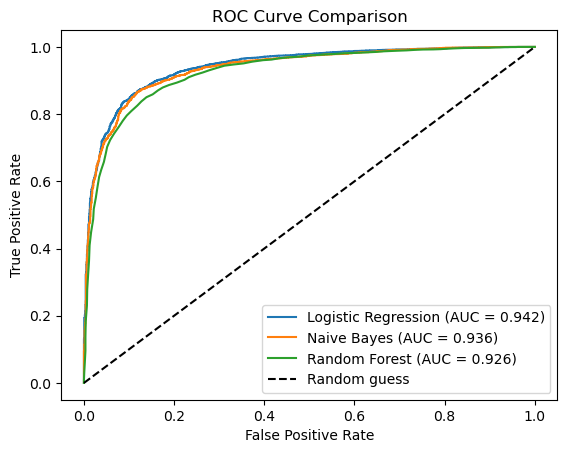

In [133]:
from sklearn.metrics import roc_curve, roc_auc_score

# Logistic Regression
fpr1, tpr1, _ = roc_curve(y_test_bin, model.predict_proba(X_test)[:, 1])
auc1 = roc_auc_score(y_test_bin, model.predict_proba(X_test)[:, 1])

# Naive Bayes
fpr2, tpr2, _ = roc_curve(y_test_bin, m.predict_proba(X_test)[:, 1])
auc2 = roc_auc_score(y_test_bin, m.predict_proba(X_test)[:, 1])

# Random Forest
fpr3, tpr3, _ = roc_curve(y_test_bin, RNN.predict_proba(X_test)[:, 1])
auc3 = roc_auc_score(y_test_bin, RNN.predict_proba(X_test)[:, 1])

plt.plot(fpr1, tpr1, label=f"Logistic Regression (AUC = {auc1:.3f})")
plt.plot(fpr2, tpr2, label=f"Naive Bayes (AUC = {auc2:.3f})")
plt.plot(fpr3, tpr3, label=f"Random Forest (AUC = {auc3:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# <center>Word Frequency</center>

In [134]:
#stop_words = set(stopwords.words('english'))
#stemmer = PorterStemmer()
#
#def clean_text(text):
#    text = text.lower()                              # lowercase
#    text = re.sub(r'<.*?>', '', text)                # remove HTML tags
#    text = re.sub(r'[^a-z\s]', '', text)             # remove punctuation/numbers
#    tokens = text.split()
#    tokens = [t for t in tokens if t not in stop_words]  # remove stopwords
#    tokens = [stemmer.stem(t) for t in tokens]       # stemming
#    return ' '.join(tokens)
#    

In [135]:
text = " ".join(review.clean_Text.dropna().astype(str))

In [301]:
# Over All Most frequent word
from nltk.tokenize import word_tokenize
from collections import Counter
import nltk

nltk.download('punkt_tab')

tokens = word_tokenize(text.lower())

word_freq = Counter(tokens)

t=dict((word_freq.most_common(50)))

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
#Frequency bar plots

Text(0, 0.5, 'Word Frequency')

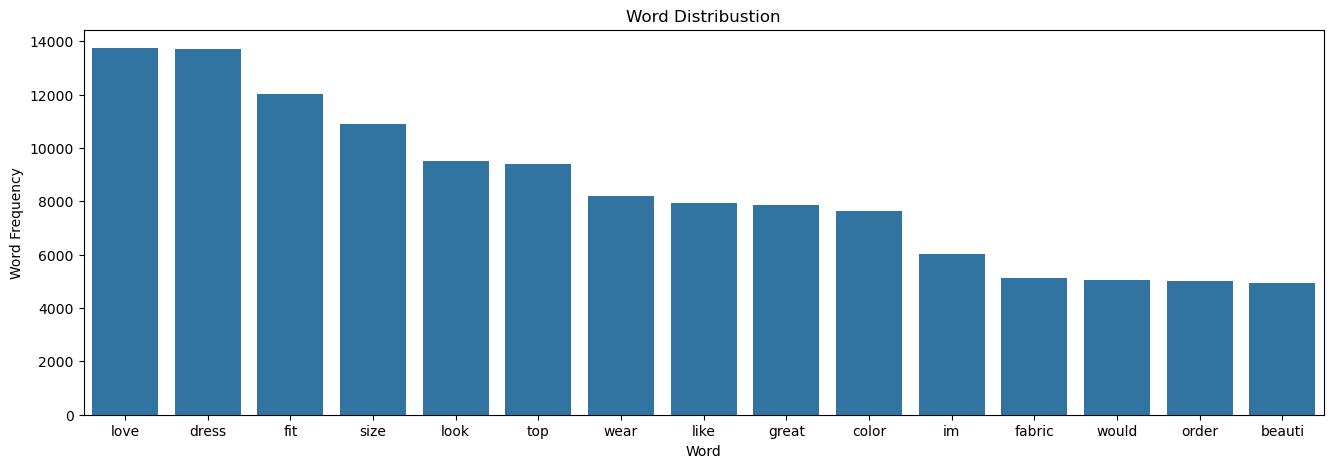

In [308]:
g=pd.DataFrame(list(t.items())[:15],columns=["Word","Frequency"])

plt.figure(figsize=(16,5))
sns.barplot(data=g,x="Word",y="Frequency")
plt.title("Word Distribustion")
plt.ylabel("Word Frequency")

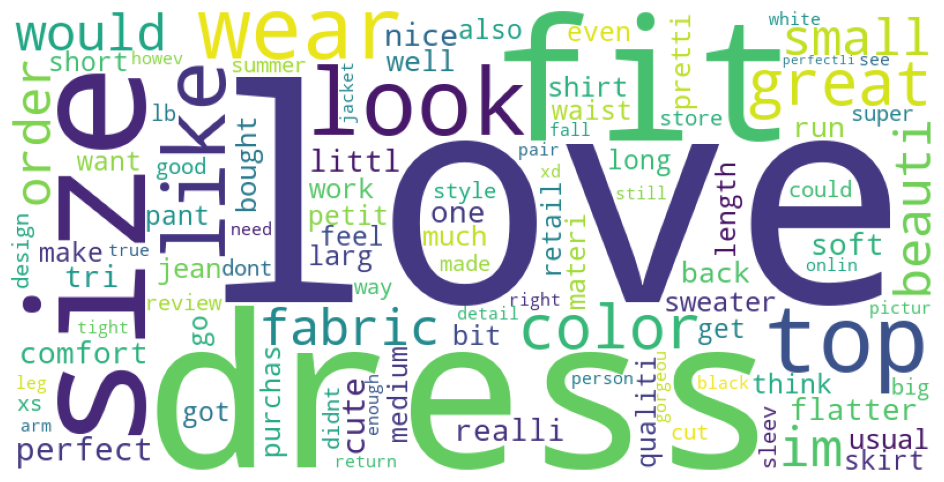

In [138]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(t)

plt.figure(figsize=(12,6))
plt.imshow(wc)
plt.axis("off")
plt.show()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


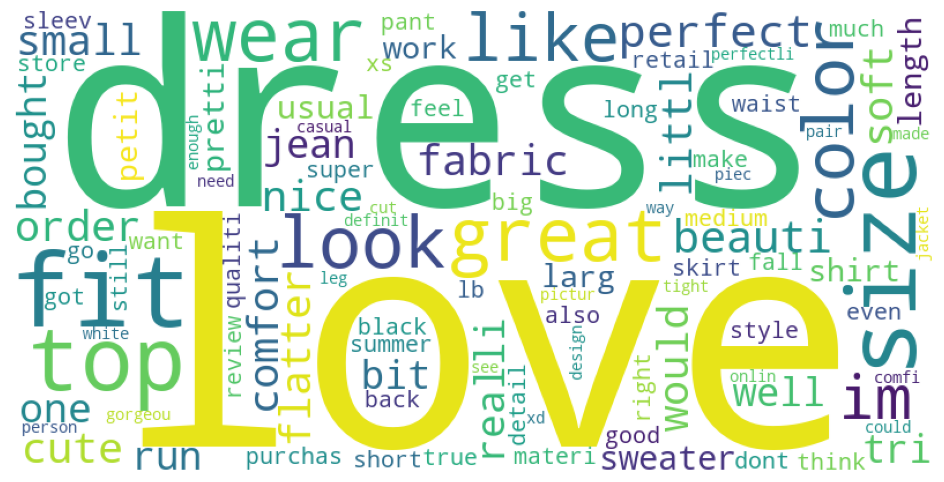

In [141]:
from nltk.tokenize import word_tokenize
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import nltk

nltk.download('punkt_tab')
Positive_ = review.loc[review.Rating >=4 , "clean_Text"].dropna()
Positive_=" ".join(Positive_)
Pos = Counter(Positive_.split())
Post=dict(Pos.most_common(100))


wc = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(Post)

plt.figure(figsize=(12,6))
plt.imshow(wc)
plt.axis("off")
plt.show()

Text(0, 0.5, 'Word Frequency')

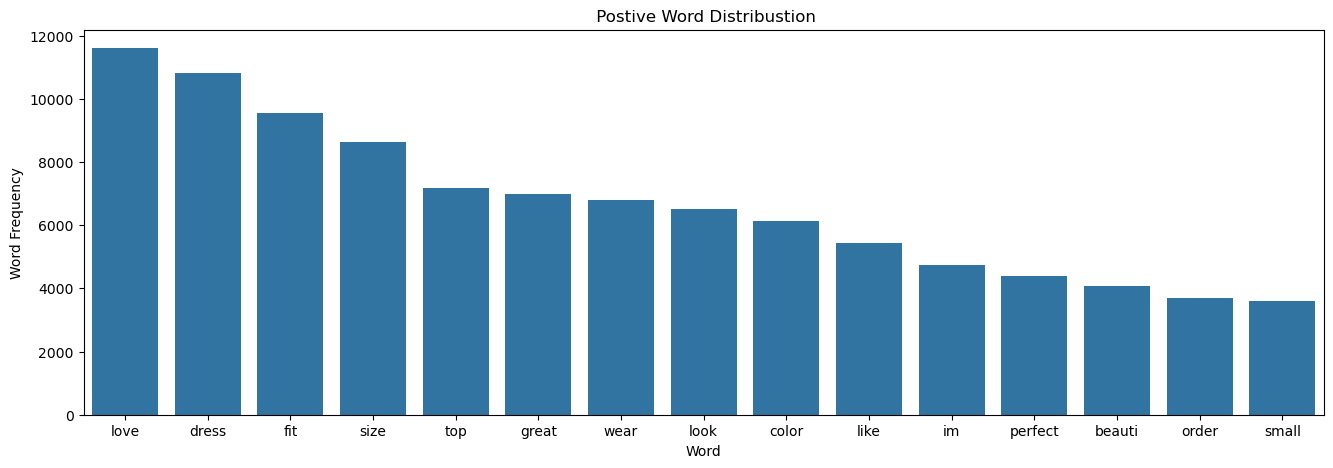

In [314]:
Pos_dis=pd.DataFrame(list(Post.items())[:15],columns=["Word","Frequency"])

plt.figure(figsize=(16,5))
sns.barplot(data=Pos_dis,x="Word",y="Frequency")
plt.title(" Postive Word Distribustion")
plt.ylabel("Word Frequency")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


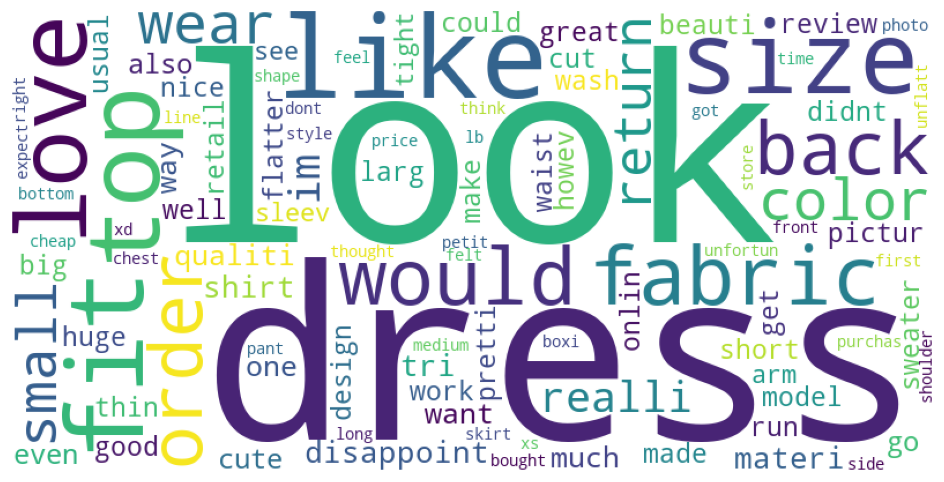

In [142]:
from nltk.tokenize import word_tokenize
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import nltk

nltk.download('punkt_tab')
Negative_ = review.loc[review.Rating <=2 , "clean_Text"].dropna()
Negative_=" ".join(Negative_)
Neg = Counter(Negative_.split())
Negative=dict(Neg.most_common(100))


wn = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(Negative)

plt.figure(figsize=(12,6))
plt.imshow(wn)
plt.axis("off")
plt.show()

Text(0, 0.5, 'Word Frequency')

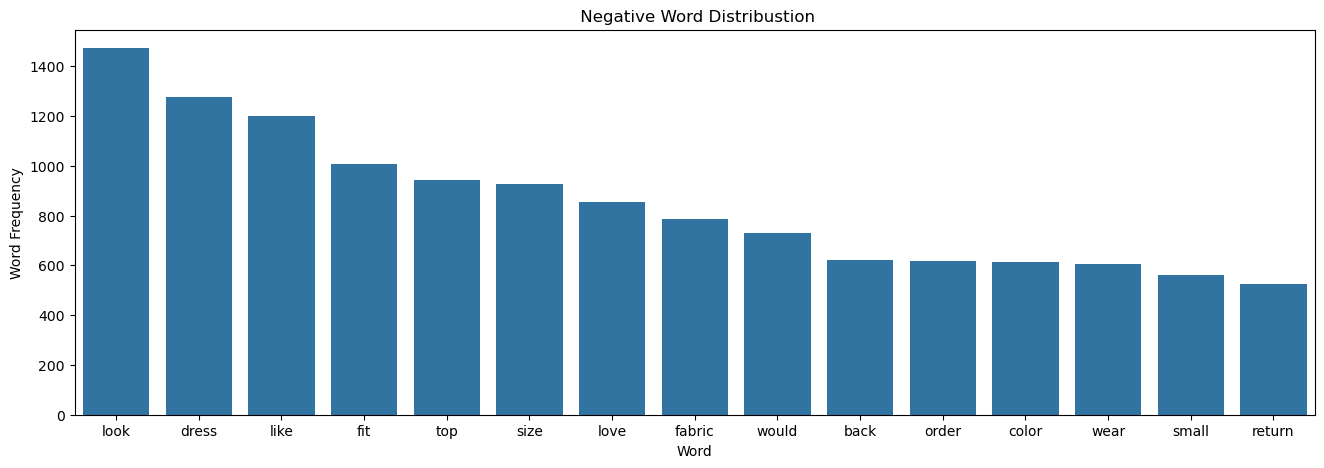

In [313]:
Ne_dis=pd.DataFrame(list(Negative.items())[:15],columns=["Word","Frequency"])

plt.figure(figsize=(16,5))
sns.barplot(data=Ne_dis,x="Word",y="Frequency")
plt.title(" Negative Word Distribustion")
plt.ylabel("Word Frequency")

# <center>Bi_gram</center>

In [316]:
from sklearn.feature_extraction.text import CountVectorizer

def top_bigrams(texts, n=15):
    cv = CountVectorizer(ngram_range=(2, 2))
    bag = cv.fit_transform(texts)
    counts = bag.sum(axis=0).A1
    df = pd.DataFrame({"Bigram": cv.get_feature_names_out(), "Count": counts})
    return df.sort_values("Count", ascending=False).head(n)

pos_bi = top_bigrams(review.loc[review.Rating >= 4, "clean_Text"].dropna())
neg_bi = top_bigrams(review.loc[review.Rating <= 2, "clean_Text"].dropna())

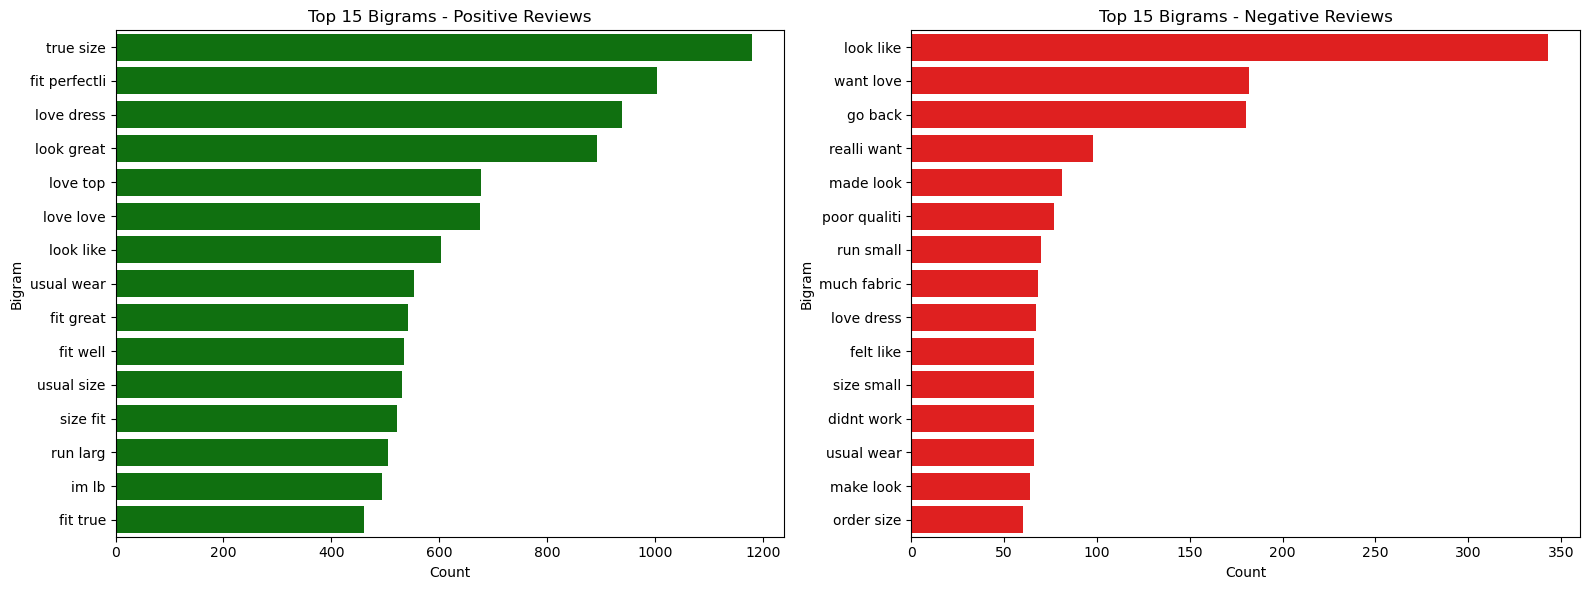

In [318]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=pos_bi, x="Count", y="Bigram", ax=ax[0], color="green")
ax[0].set_title("Top 15 Bigrams - Positive Reviews")

sns.barplot(data=neg_bi, x="Count", y="Bigram", ax=ax[1], color="red")
ax[1].set_title("Top 15 Bigrams - Negative Reviews")

plt.tight_layout()
plt.show()



[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


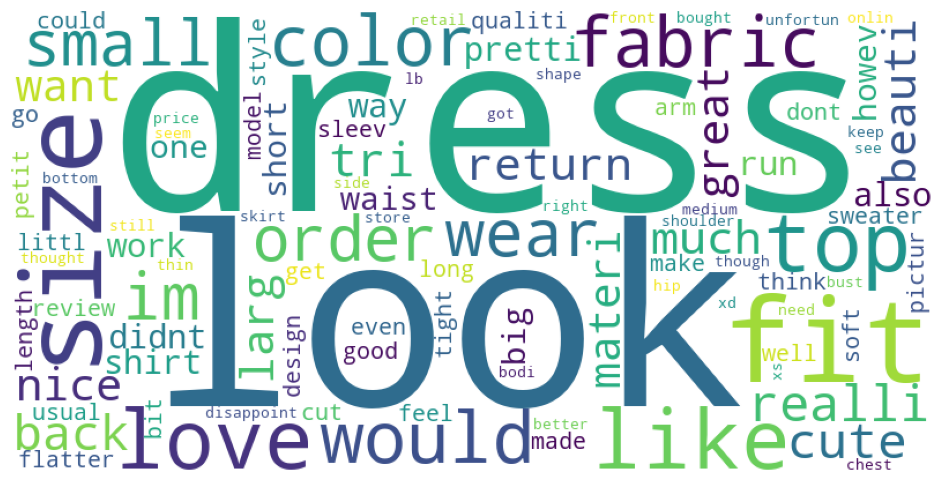

In [143]:
from nltk.tokenize import word_tokenize
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import nltk

nltk.download('punkt_tab')
Ne=review.loc[review.Rating ==3 , "clean_Text"].dropna()
Ne=" ".join(Ne)
Ne = Counter(Ne.split())
Neutral=dict(Ne.most_common(100))


wn = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(Neutral)

plt.figure(figsize=(12,6))
plt.imshow(wn)
plt.axis("off")
plt.show()

Text(0, 0.5, 'Word Frequency')

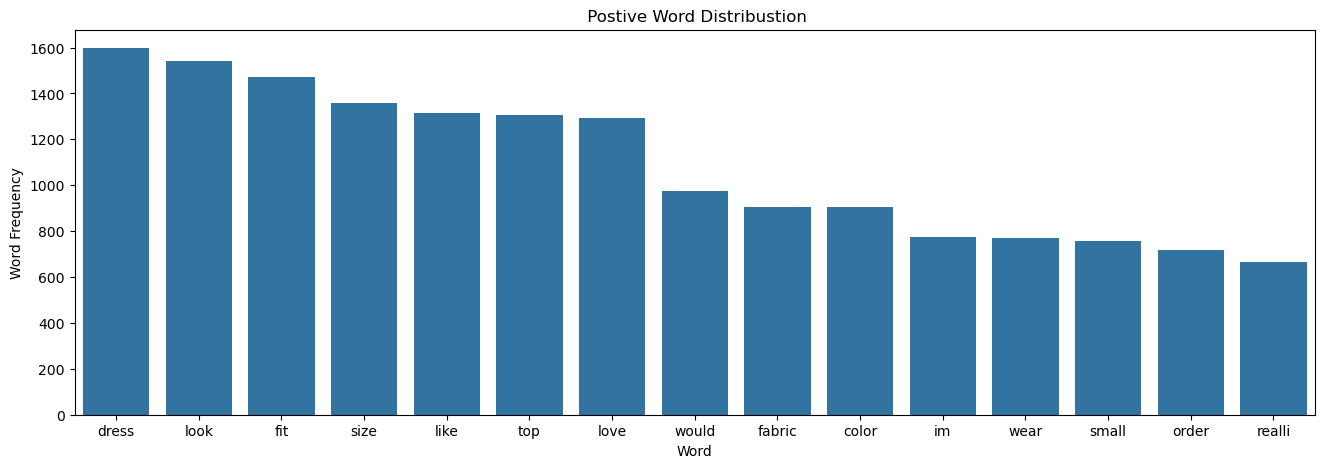

In [315]:
Neut_dis=pd.DataFrame(list(Neutral.items())[:15],columns=["Word","Frequency"])

plt.figure(figsize=(16,5))
sns.barplot(data=Neut_dis,x="Word",y="Frequency")
plt.title(" Postive Word Distribustion")
plt.ylabel("Word Frequency")

# <center>Sentiment Analysis</center>

In [146]:
review["Sentiment_"] = np.where(review.Rating >=4,"Positive",np.where(review.Rating <=2,"Negative","Neutral"))

In [147]:
review.Sentiment_.value_counts()

Sentiment_
Postive     17448
Neutral      2823
Negative     2370
Name: count, dtype: int64

In [148]:
review.Sentiment_.value_counts() / review.shape[0] * 100

Sentiment_
Postive     77.063734
Neutral     12.468531
Negative    10.467736
Name: count, dtype: float64

Text(0.5, 1.0, 'Sentiment Distribution')

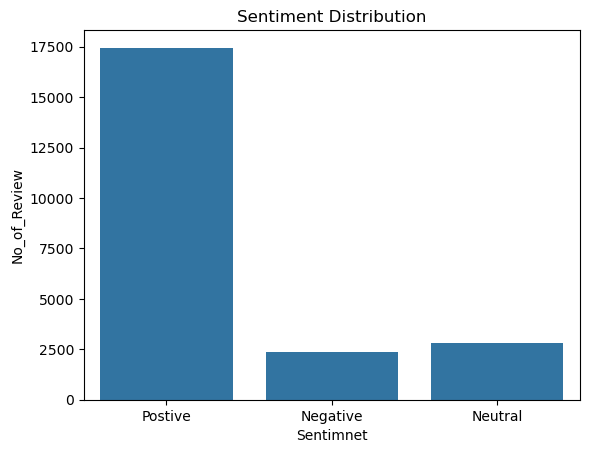

In [320]:
sns.countplot(review,x = review.Sentiment_,order=["Postive","Negative","Neutral"])

plt.ylabel("No_of_Review")
plt.xlabel("Sentimnet")
plt.title("Sentiment Distribution")

# <center>Category,SubCategory and Product  by Sentiment Analysis</center>

In [164]:
review.pivot_table(
    index="Category",
    columns="Sentiment_",
    aggfunc="size",
    fill_value=0
)

Sentiment_,Negative,Neutral,Postive
Category,,,
General,142900,174000,1019600
General Petite,81500,92900,609300
Initmates,12600,15400,114600
Unknown,0,0,1300


In [161]:
sentiment_pct = pd.crosstab(
    review["Category"],
    review["Sentiment_"],
    normalize="index"
).mul(100).round(2)

sentiment_pct

Sentiment_,Negative,Neutral,Postive
Category,,,
General,10.69,13.02,76.29
General Petite,10.40,11.85,77.75
Initmates,8.84,10.80,80.36
Unknown,0.00,0.00,100.00


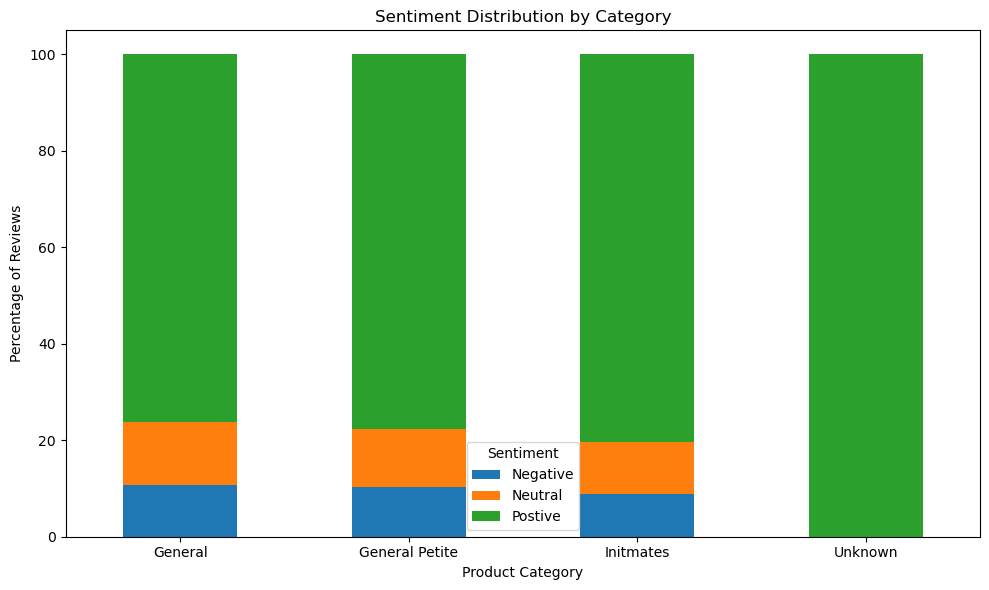

In [162]:
sentiment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [281]:
Category_0= pd.crosstab(index=review["Subcategory1"],
                      columns=review["Sentiment_"],values=review["Product_ID"],
                        aggfunc="count",normalize="index").mul(100).sort_values(["Postive","Negative"],ascending =[False,False])

In [282]:
Category_0

Sentiment_,Negative,Neutral,Postive
Subcategory1,,,
Unknown,0.000000,0.000000,100.000000
Intimate,8.892922,10.707804,80.399274
Jackets,10.778443,8.982036,80.239521
Bottoms,8.656472,11.114145,80.229383
Tops,10.907643,12.937898,76.154459
Dresses,11.082181,13.506916,75.410903
Trend,17.796610,16.101695,66.101695


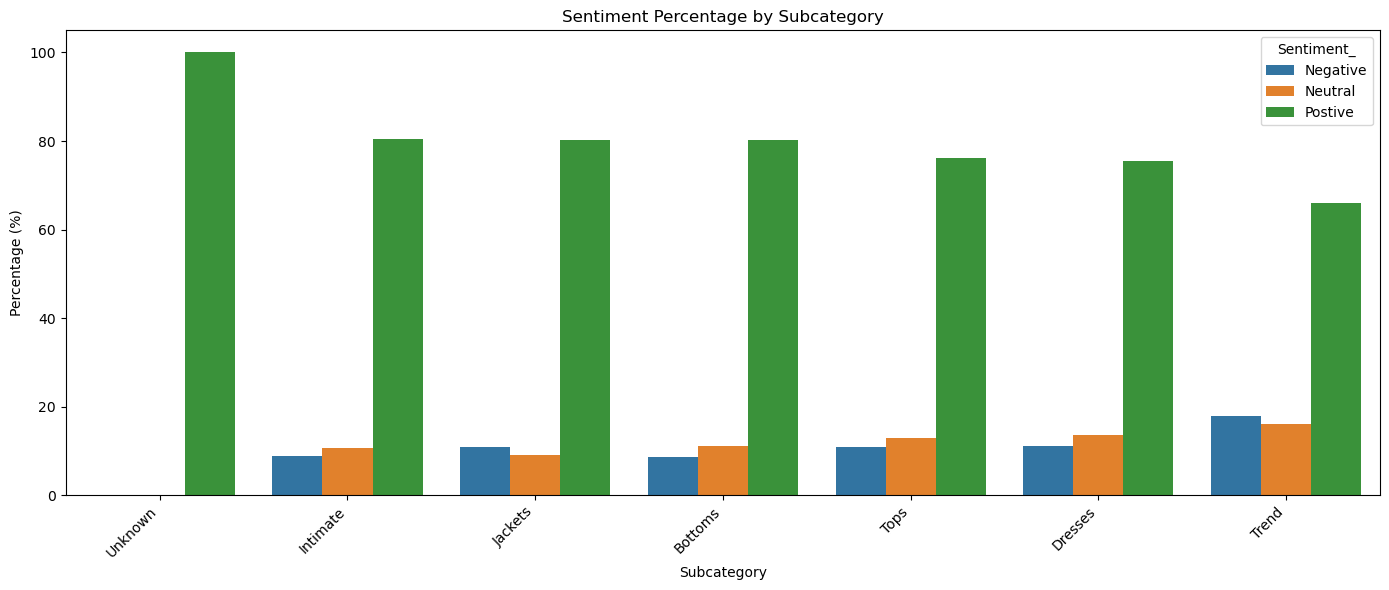

In [283]:
# Convert wide format to long format
Category_1 = Category_0.reset_index().melt(
    id_vars="Subcategory1",
    var_name="Sentiment_",
    value_name="Percentage"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=Category_1,
    x="Subcategory1",
    y="Percentage",
    hue="Sentiment_"
)

plt.xticks(rotation=45, ha="right")
plt.title("Sentiment Percentage by Subcategory")
plt.ylabel("Percentage (%)")
plt.xlabel("Subcategory")
plt.tight_layout()
plt.show()

In [192]:
Category_2 = pd.crosstab(index=review["SubCategory2"],
                      columns=review["Sentiment_"],values=review["Product_ID"],aggfunc="count",normalize="index").mul(100).sort_values(["Postive","Negative"],
                                                                                                                                       ascending =[False,False])

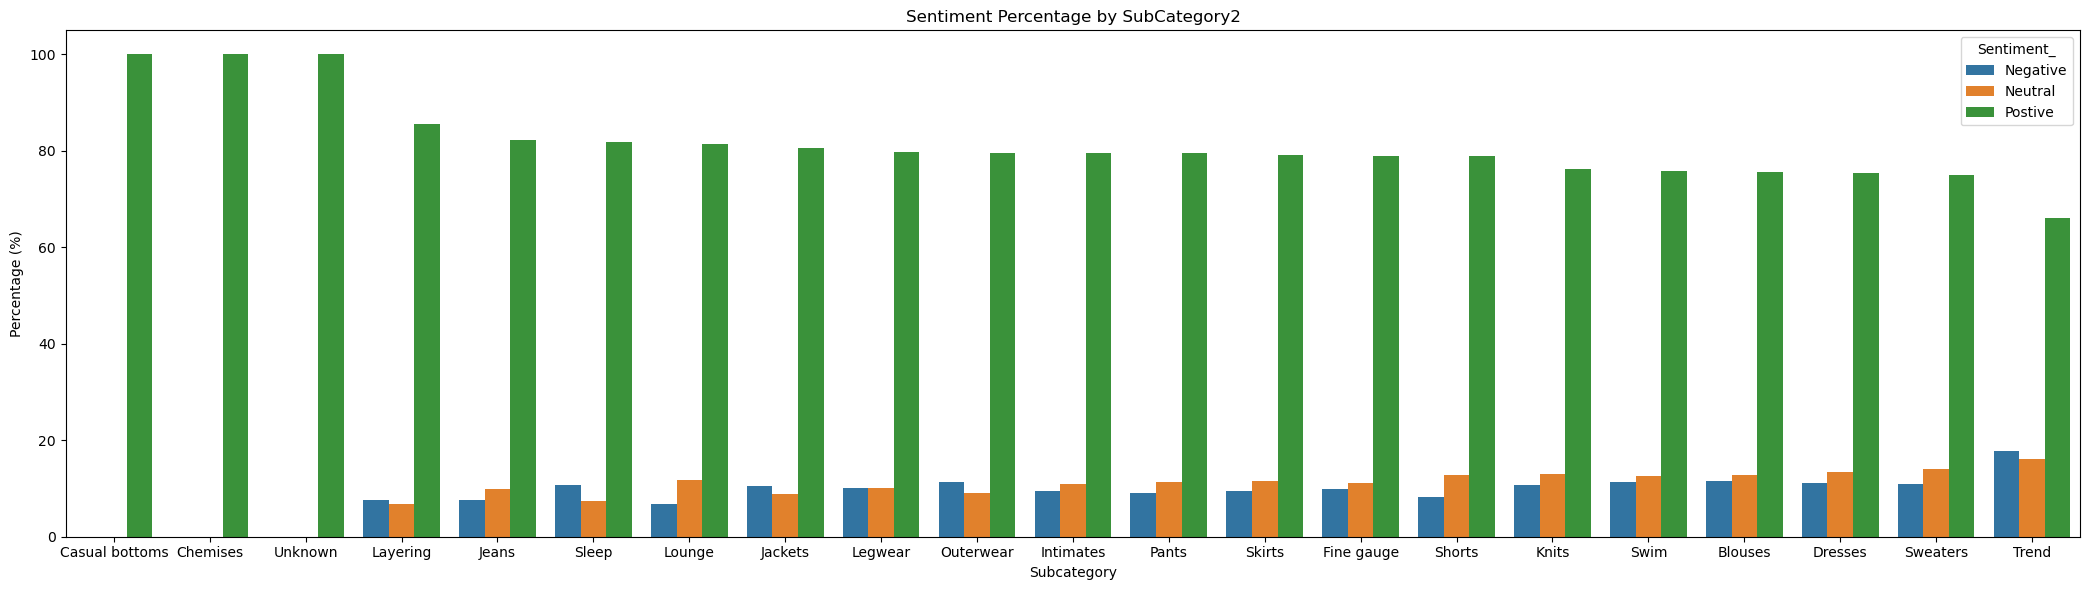

In [205]:
plt.figure(figsize=(21, 6))
sns.barplot(data = Category_2 , x="SubCategory2",y="Percentage",hue="Sentiment_")
plt.title("Sentiment Percentage by SubCategory2")
plt.ylabel("Percentage (%)")
plt.xlabel("Subcategory")
plt.tight_layout()
plt.show()

In [210]:
Product = pd.crosstab(index=review["Product_ID"],
                      columns=review["Sentiment_"],values=review["Product_ID"],aggfunc="count",normalize="index").mul(100).sort_values(["Postive","Negative"],
                                                                                                                                       ascending =[False,False]).head(10)

In [217]:
p = Product.reset_index().melt(id_vars="Product_ID",
    var_name="Sentiment_",
    value_name="Percentage"
)

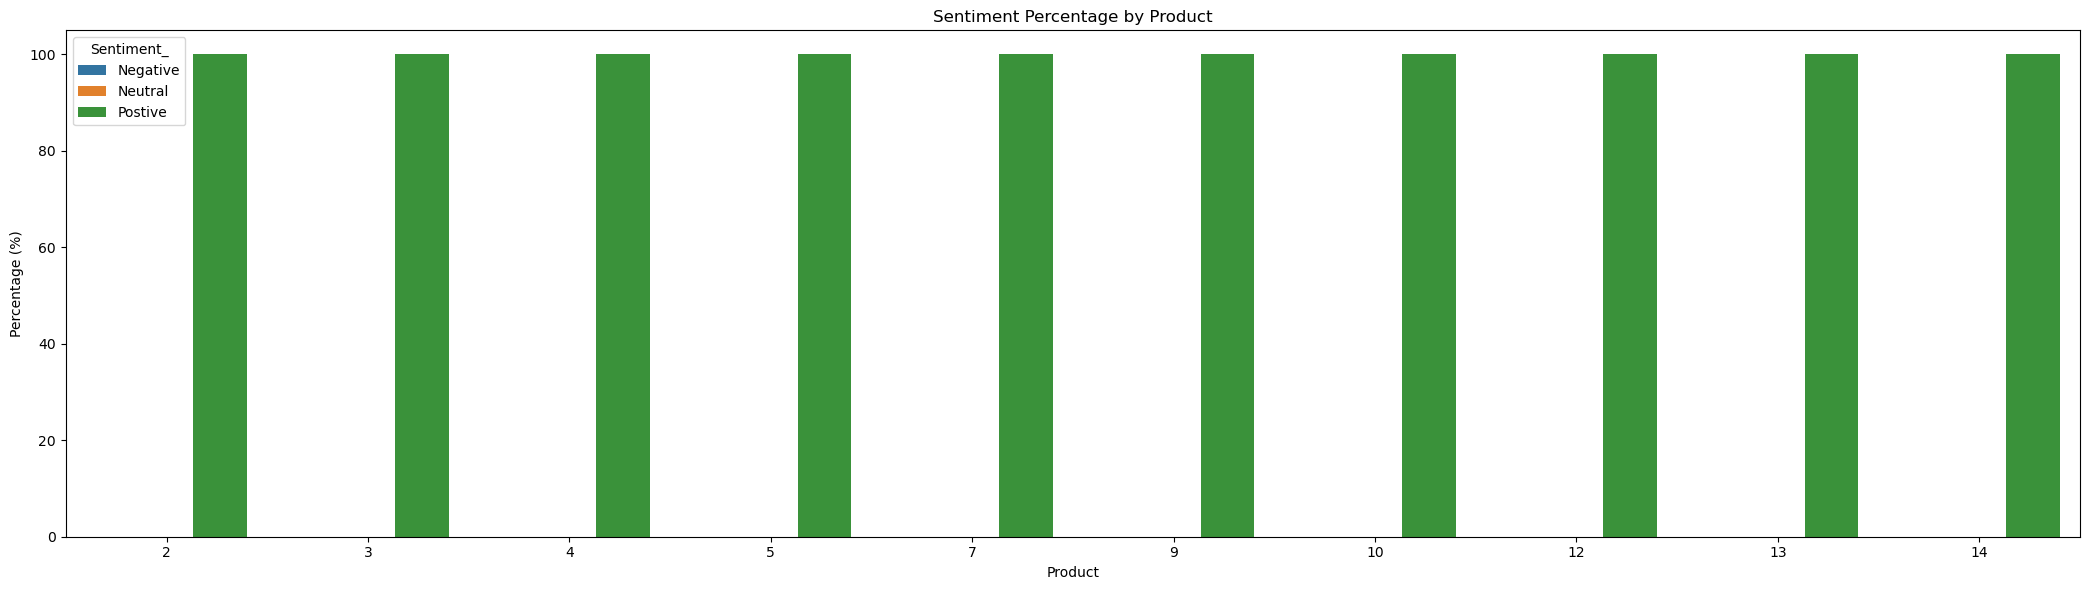

In [218]:
plt.figure(figsize=(21, 6))
sns.barplot(data =p , x="Product_ID",y="Percentage",hue="Sentiment_")
plt.title("Sentiment Percentage by Product")
plt.ylabel("Percentage (%)")
plt.xlabel("Product")
plt.tight_layout()
plt.show()

# <center>Location  by Sentiment Analysis</center>

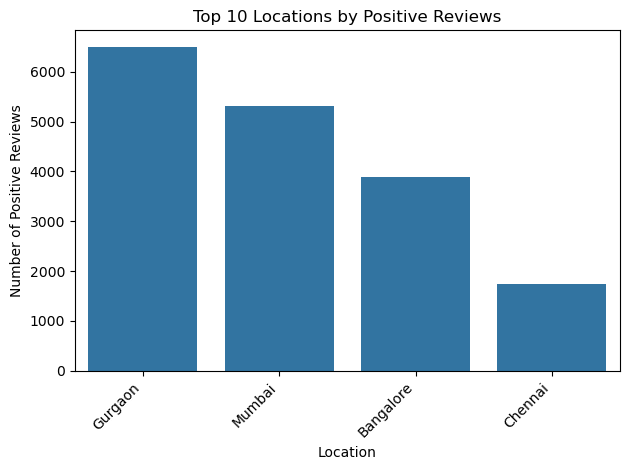

In [249]:
# # Top 10 Locations with Positive Sentiment
loc = review.loc[review.Sentiment_ == "Postive"]
l=loc.groupby("Location")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)
sns.barplot(data=l,x="Location",y="Sentiment_")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Location")
plt.ylabel("Number of Positive Reviews")
plt.title("Top 10 Locations by Positive Reviews")
plt.tight_layout()
plt.show()

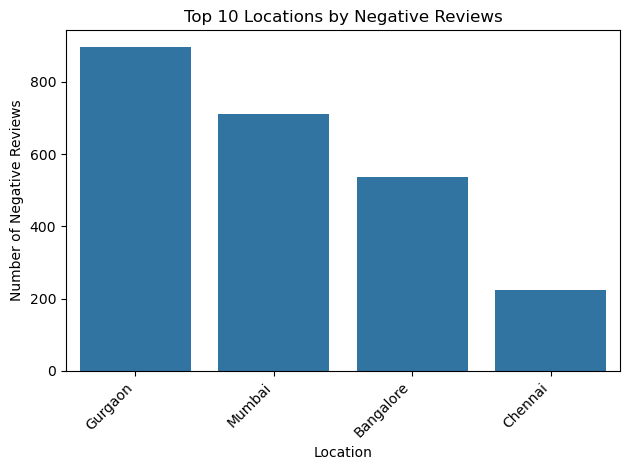

In [251]:
# # Top 10 Locations with Negative Sentiment
Ne = review.loc[review.Sentiment_ == "Negative"]
N=Ne.groupby("Location")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)
sns.barplot(data=N,x="Location",y="Sentiment_")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Location")
plt.ylabel("Number of Negative Reviews")
plt.title("Top 10 Locations by Negative Reviews")
plt.tight_layout()
plt.show()

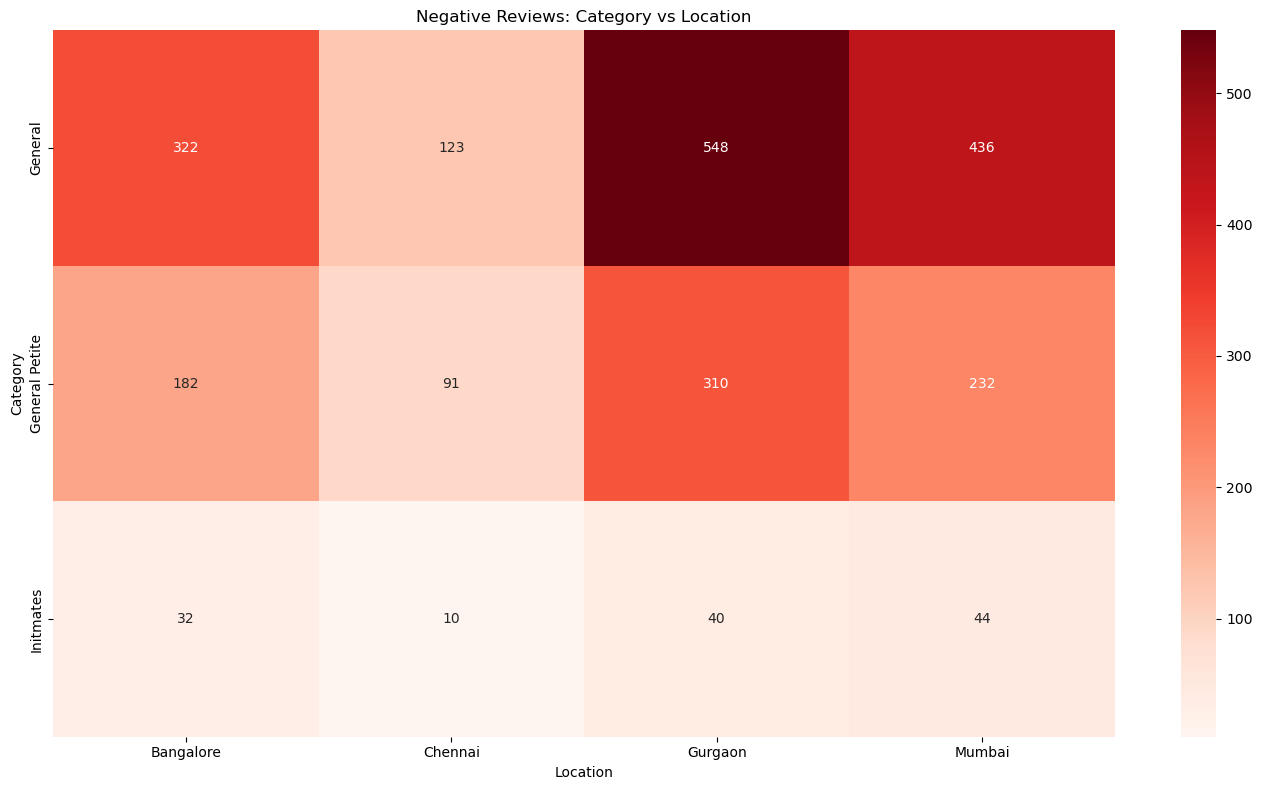

In [253]:
#cv  Negative Sentiment Analysis by Category and Location
negative = review.loc[review["Sentiment_"] == "Negative"]
pivot = pd.crosstab(
    index=negative["Category"],
    columns=negative["Location"]
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    pivot,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("Negative Reviews: Category vs Location")
plt.xlabel("Location")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# <center>Age by Sentiment Analysis</center>

C:\Users\Asus\AppData\Local\Temp\ipykernel_26144\15408145.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  A=Ag.groupby("Age_Group")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)


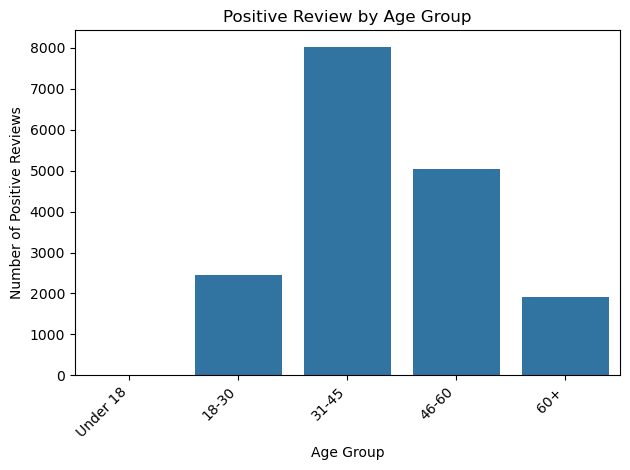

In [257]:

# Positive Sentiment Analysis by Age Group
Ag = review.loc[review.Sentiment_ == "Postive"]
A=Ag.groupby("Age_Group")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)
sns.barplot(data=A,x="Age_Group",y="Sentiment_")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Age Group")
plt.ylabel("Number of Positive Reviews")
plt.title("Positive Review by Age Group")
plt.tight_layout()
plt.show()

# Conclusion: The 31–45 age group has the highest number of positive reviews compared to the other age groups.

C:\Users\Asus\AppData\Local\Temp\ipykernel_26144\328840863.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  J=Neg.groupby("Age_Group")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)


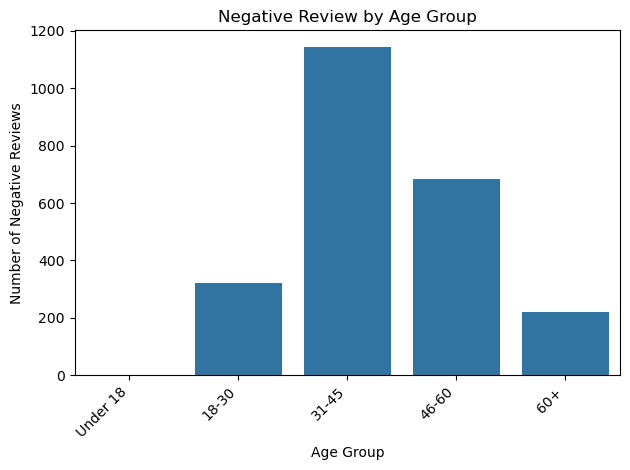

In [259]:
# Negative Sentiment Analysis by Age Group
Neg = review.loc[review.Sentiment_ == "Negative"]
J=Neg.groupby("Age_Group")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index = True)
sns.barplot(data=J,x="Age_Group",y="Sentiment_")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Age Group")
plt.ylabel("Number of Negative Reviews")
plt.title("Negative Review by Age Group")
plt.tight_layout()
plt.show()

# Conclusion: The 31–45 age group has the highest number of Negative reviews compared to the other age groups.

C:\Users\Asus\AppData\Local\Temp\ipykernel_26144\1141395747.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  h=He.pivot_table(index="Category",columns="Age_Group",values="Product_ID",aggfunc="count")


<Axes: xlabel='Age_Group', ylabel='Category'>

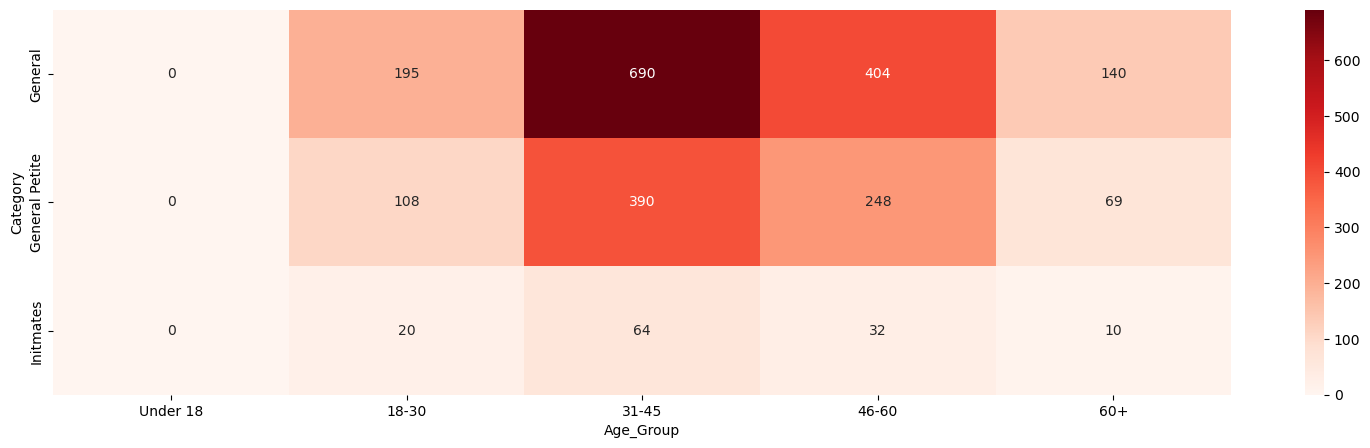

In [273]:
He = review.loc[review.Sentiment_ == "Negative"]

h=He.pivot_table(index="Category",columns="Age_Group",values="Product_ID",aggfunc="count")

plt.figure(figsize=(19,5))
sns.heatmap(data=h,annot=True,fmt="d",
    cmap="Reds")


# Conclusion: The 31–45 age group has the highest number of Negative reviews compared to the other age groups for Genreal Category.

# <center> Channel by Sentiment Analysis</center>

Text(0, 0.5, 'No_of_Review')

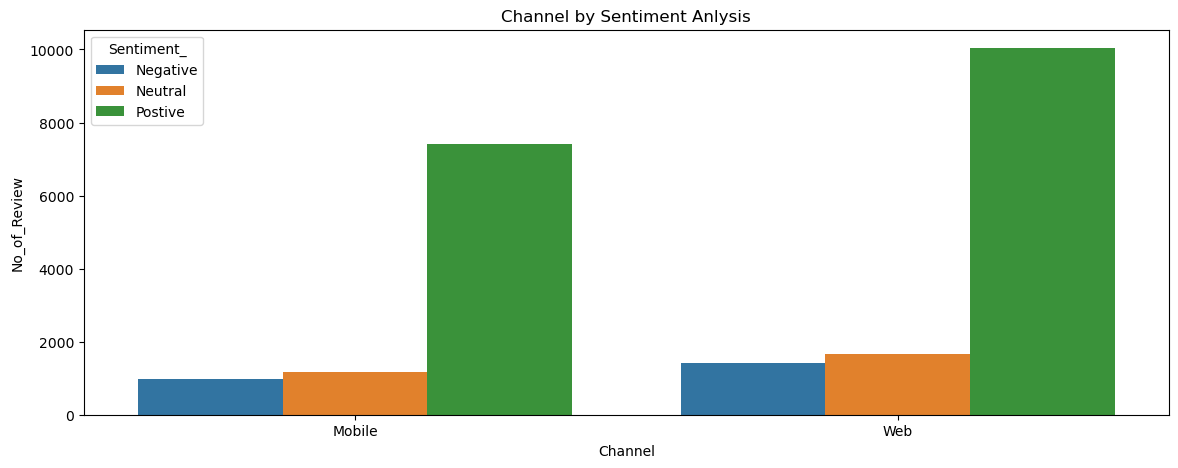

In [290]:
w=pd.crosstab(index=review["Channel"],columns=review["Sentiment_"],values="Product_ID",aggfunc="count")
c=w.reset_index().melt(id_vars="Channel",var_name="Sentiment_",value_name="Count")
plt.figure(figsize=(14,5))
sns.barplot(data=c,x="Channel",y="Count",hue="Sentiment_")
plt.title("Channel by Sentiment Anlysis")
plt.ylabel("No_of_Review")

#This may indicate that customers using the Web platform are sharing more positive feedback. However,
#comparing the percentage of positive reviews across both channels would provide a fairer assessment of customer satisfaction.

Text(0, 0.5, 'No_of_Review')

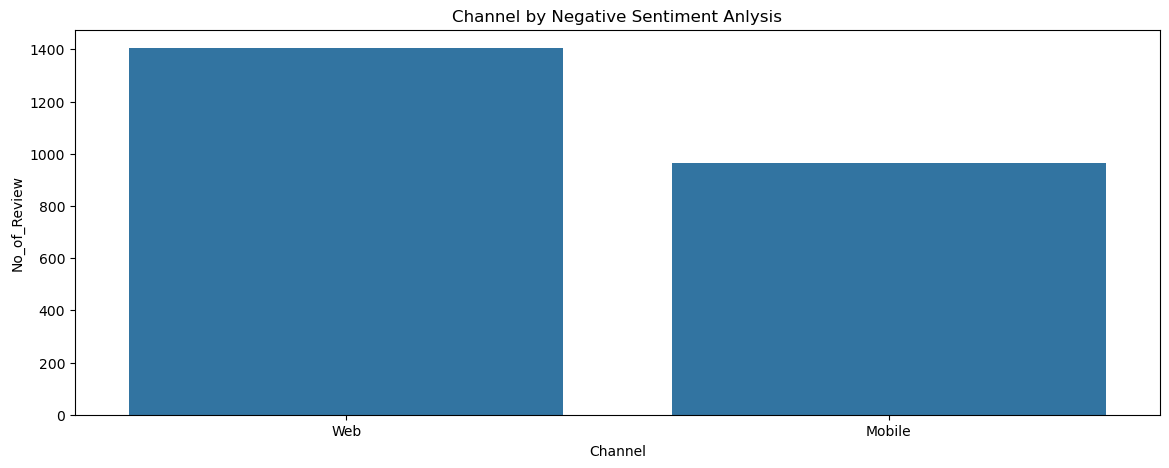

In [296]:
Ch = review.loc[review.Sentiment_ == "Negative"]
ff = Ch.groupby("Channel")["Sentiment_"].count().reset_index().sort_values("Sentiment_",ascending = False,ignore_index=True)

plt.figure(figsize=(14,5))
sns.barplot(data=ff,x="Channel",y="Sentiment_")
plt.title("Channel by Negative Sentiment Anlysis")
plt.ylabel("No_of_Review")

#A high number of negative reviews on the Web channel may indicate customer dissatisfaction with the online shopping experience. 
#Potential customers may hesitate to make purchases if they frequently encounter negative feedback. 
#The business should investigate the reasons behind these reviews and improve the customer experience on the Web platform.

# <center>Sentiment or Recommend Analysis </center>

In [298]:
# Sentiment by Recommended Analysis
se = pd.crosstab(index=review["Sentiment_"],columns=review["Recommend_Flag"] , values="Product_ID",aggfunc="count")

In [299]:
#Customers with positive sentiment are more likely to recommend products to other customers compared to
#customers with other sentiment categories.
#A total of 17,261 positive reviews are associated with recommendations to other customers.

Recommend_Flag,0,1
Sentiment_,,
Negative,2261,109
Neutral,1653,1170
Postive,187,17261


In [300]:
# Negative Sentiment by Recommded
Nu = review.loc[review.Sentiment_ == "Negative"]
ll= pd.crosstab(index=Nu["Sentiment_"],columns=Nu["Recommend_Flag"] , values="Product_ID",aggfunc="count")
ll

#There are 2,261 negative reviews overall, but only 109 of these reviews are associated with product recommendations.

Recommend_Flag,0,1
Sentiment_,,
Negative,2261,109


# <center>Recommend Flag model aur drivers</center>

In [321]:
rX = review["clean_Text"]
ry = review["Recommend_Flag"]          # 1 = recommend, 0 = not recommend

rX_train, rX_test, ry_train, ry_test = train_test_split(
    rX, ry, test_size=0.3, random_state=123, stratify=y
)

tfidf_rec = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
Xtr = tfidf_rec.fit_transform(rX_train)
Xte = tfidf_rec.transform(rX_test)

              precision    recall  f1-score   support

           0       0.65      0.85      0.74      1231
           1       0.96      0.90      0.93      5562

    accuracy                           0.89      6793
   macro avg       0.81      0.87      0.83      6793
weighted avg       0.91      0.89      0.90      6793

ROC-AUC: 0.947


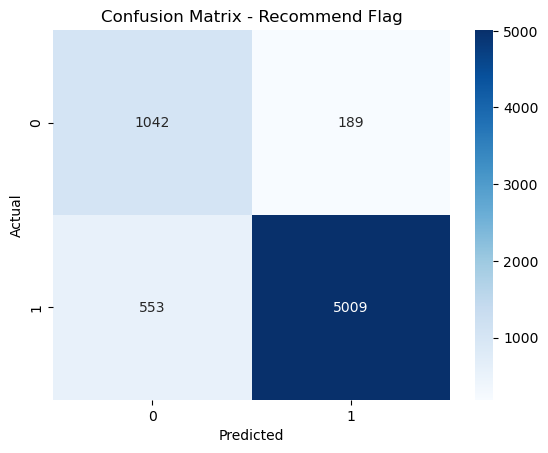

In [324]:
rec_model = LogisticRegression(max_iter=1000, class_weight="balanced")
rec_model.fit(Xtr, ry_train)

pred = rec_model.predict(Xte)
print(classification_report(ry_test, pred))
print("ROC-AUC:", round(roc_auc_score(ry_test, rec_model.predict_proba(Xte)[:, 1]), 3))

sns.heatmap(confusion_matrix(ry_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Recommend Flag")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<Axes: >

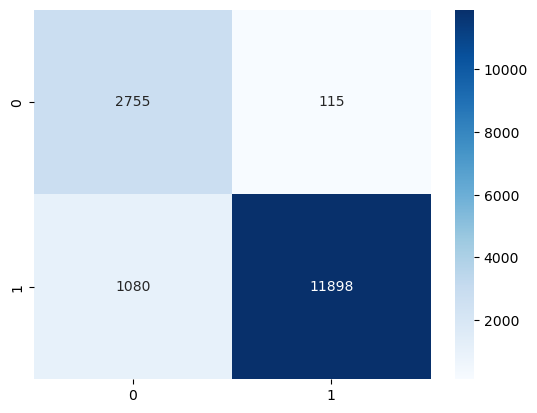

In [328]:
sns.heatmap(confusion_matrix(ry_train, rec_model.predict(Xtr,)), annot=True, fmt="d", cmap="Blues")

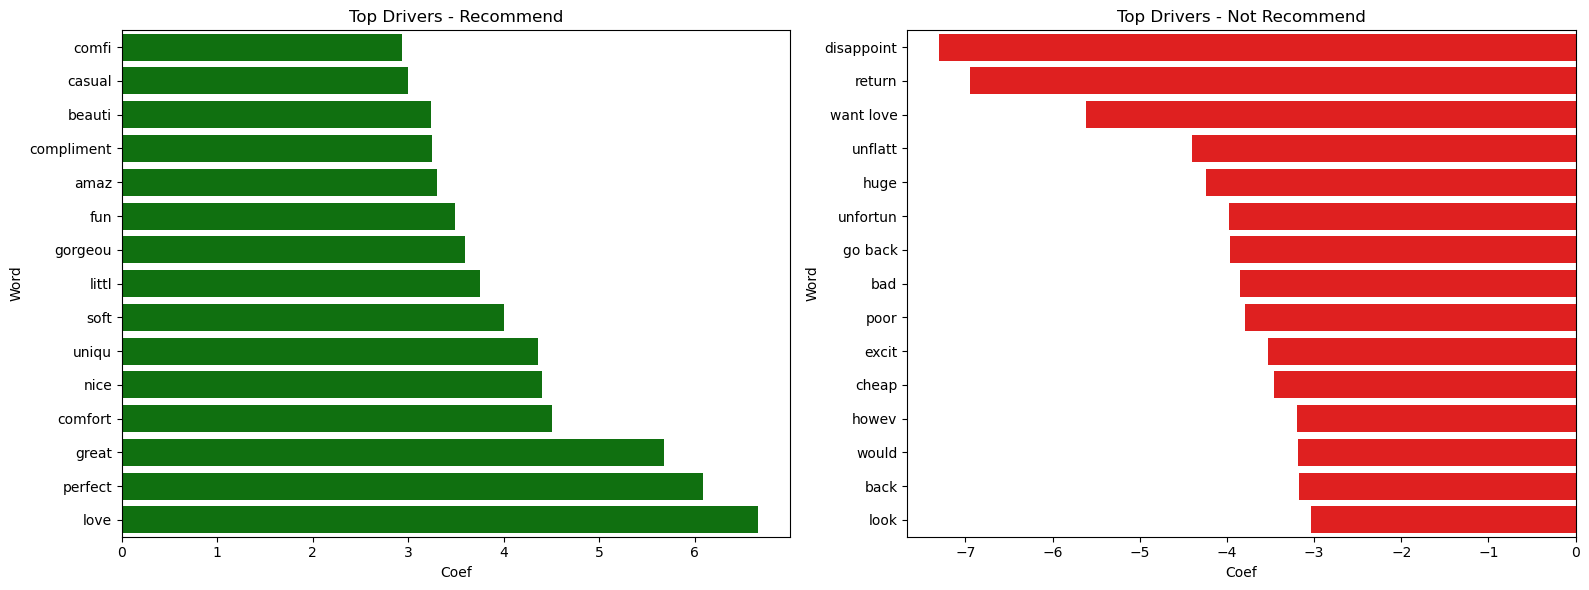

In [329]:
words = tfidf_rec.get_feature_names_out()
coef = rec_model.coef_[0]

drv = pd.DataFrame({"Word": words, "Coef": coef}).sort_values("Coef")

top_rec = drv.tail(15)      # recommend ki taraf dhakelte hain
top_not = drv.head(15)      # not recommend ki taraf dhakelte hain

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=top_rec, x="Coef", y="Word", ax=ax[0], color="green")
ax[0].set_title("Top Drivers - Recommend")
sns.barplot(data=top_not, x="Coef", y="Word", ax=ax[1], color="red")
ax[1].set_title("Top Drivers - Not Recommend")
plt.tight_layout()
plt.show()

In [330]:
for col in ["Category", "Channel", "Age_Group"]:
    print(review.groupby(col, observed=True)["Recommend_Flag"].mean().round(3), "\n")

Category
General           0.813
General Petite    0.823
Initmates         0.848
Unknown           1.000
Name: Recommend_Flag, dtype: float64 

Channel
Mobile    0.822
Web       0.817
Name: Recommend_Flag, dtype: float64 

Age_Group
Under 18    1.000
18-30       0.809
31-45       0.810
46-60       0.826
60+         0.852
Name: Recommend_Flag, dtype: float64 



# <center>Rating prediction </center>

In [337]:
XX = review["clean_Text"]

              precision    recall  f1-score   support

           1       0.35      0.41      0.38       246
           2       0.30      0.37      0.33       465
           3       0.38      0.40      0.39       847
           4       0.43      0.46      0.44      1473
           5       0.84      0.78      0.81      3762

    accuracy                           0.62      6793
   macro avg       0.46      0.48      0.47      6793
weighted avg       0.64      0.62      0.63      6793



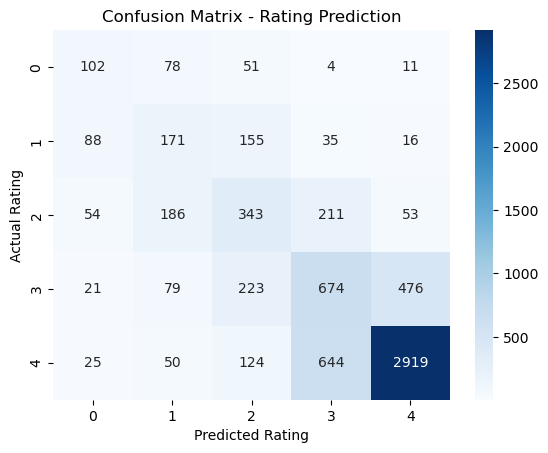

In [338]:
y_r = review["Rating"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    XX, y_r, test_size=0.3, random_state=123, stratify=y_r
)

tfidf_r = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
Xrtr = tfidf_r.fit_transform(Xr_train)
Xrte = tfidf_r.transform(Xr_test)

rate_model = LogisticRegression(max_iter=2000, class_weight="balanced")
rate_model.fit(Xrtr, yr_train)

pr = rate_model.predict(Xrte)
print(classification_report(yr_test, pr))

sns.heatmap(confusion_matrix(yr_test, pr), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Rating Prediction")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.show()

In [339]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

reg = Ridge(alpha=1.0)
reg.fit(Xrtr, yr_train)
pred_r = reg.predict(Xrte)

print("MAE :", round(mean_absolute_error(yr_test, pred_r), 3))
print("RMSE:", round(mean_squared_error(yr_test, pred_r) ** 0.5, 3))

MAE : 0.558
RMSE: 0.738


 # <center>Toping _Mining</center>

In [341]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

cv = CountVectorizer(max_df=0.8, min_df=10, max_features=5000)
dtm = cv.fit_transform(review["clean_Text"])

In [342]:
#max_df=0.8: jo word 80% se zyada reviews mein hai (jaise “dress”) wo hata do.
# min_df=10: jo word 10 se kam reviews mein hai wo hata do.

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 590365 stored elements and shape (22641, 2603)>

In [343]:
lda = LatentDirichletAllocation(n_components=5, random_state=123, learning_method="batch")
lda.fit(dtm)

,n_components,5
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [347]:
# Step 1: Pehle Topic column banao (ye missing tha)
topic_dist = lda.transform(dtm)
review["Topic"] = topic_dist.argmax(axis=1) + 1

# Step 2: Ab top words aur sample reviews dekho
words = cv.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = [words[j] for j in topic.argsort()[-10:][::-1]]
    print(f"\nTopic {i+1}: {', '.join(top_words)}")
    for s in review.loc[review["Topic"] == i+1, "text"].head(3):
        print("   -", s[:120])


Topic 1: size, fit, dress, im, small, order, love, wear, pant, jean
   -  Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered
   - Some major design flaws I had such high hopes for this dress and really wanted it to work for me. i initially ordered th
   - Flattering I love this dress. i usually get an xs but it runs a little snug in bust so i ordered up a size. very flatter

Topic 2: top, love, color, size, fit, great, wear, sweater, soft, look
   - Looks great with white pants Took a chance on this blouse and so glad i did. i wasn't crazy about how the blouse is phot
   - Great layering piece This sweater is so comfy and classic - it balances a quirky hand-knit look with a beautiful color a
   - Beautifully cut lightweight coat Just ordered this in a small for me (5'6", 135, size 4) and medium for my mom (5'3", 13

Topic 3: look, dress, like, fabric, love, back, color, tri, one, beauti
   - Dress looks like it's mad

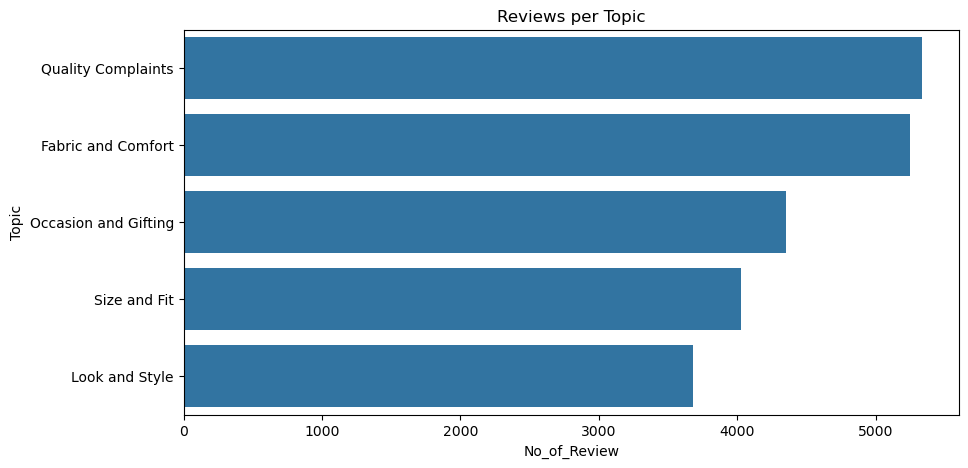

Sentiment_            Negative  Neutral  Postive
Topic_Name                                      
Fabric and Comfort         1.8      5.0     93.3
Look and Style            29.2     21.5     49.3
Occasion and Gifting      19.9     28.6     51.5
Quality Complaints         1.8      2.2     96.1
Size and Fit               6.0     10.2     83.8


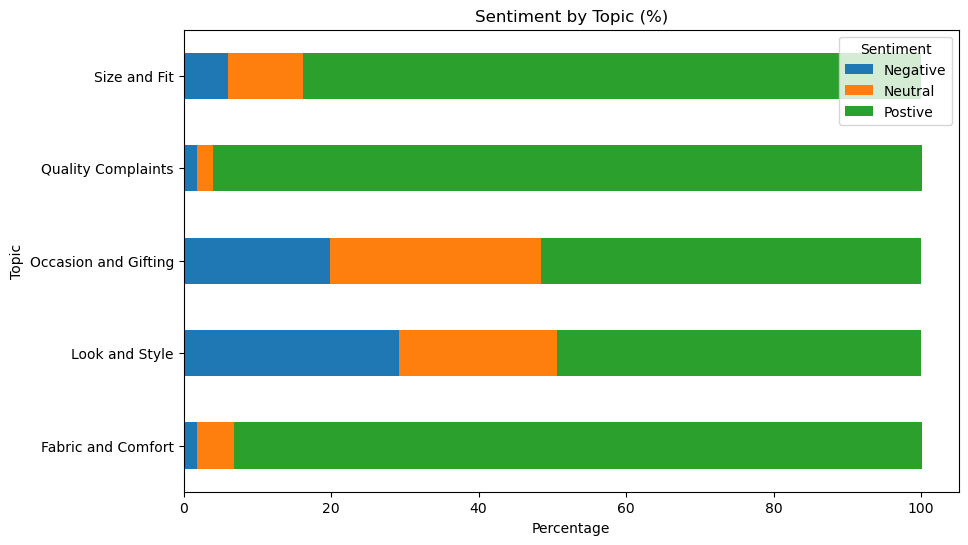

Topic_Name
Look and Style          3.39
Occasion and Gifting    3.49
Size and Fit            4.35
Fabric and Comfort      4.61
Quality Complaints      4.75
Name: Rating, dtype: float64


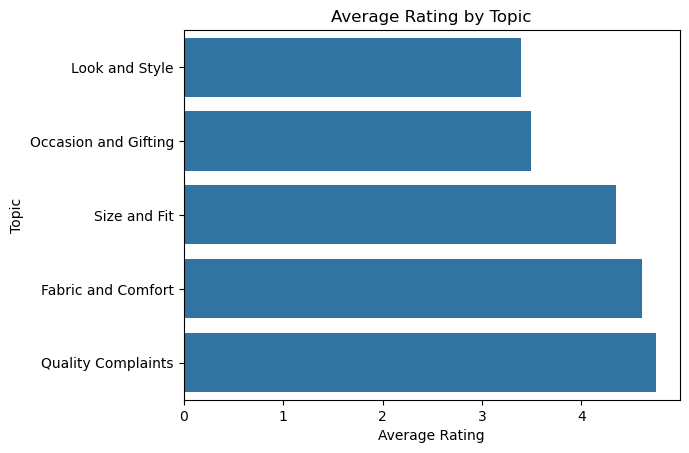

Topic_Name
Look and Style          55.3
Occasion and Gifting    62.0
Size and Fit            89.0
Fabric and Comfort      96.1
Quality Complaints      97.1
Name: Recommend_Flag, dtype: float64


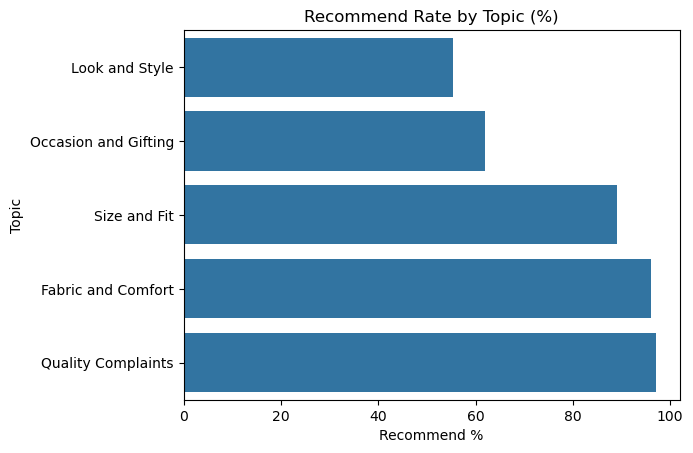

In [351]:
#3. Topics ko naam do (apne top words dekh ke badalna) ----------
topic_names = {
    1: "Size and Fit",
    2: "Fabric and Comfort",
    3: "Look and Style",
    4: "Quality Complaints",
    5: "Occasion and Gifting"
}
review["Topic_Name"] = review["Topic"].map(topic_names)

# ---------- 4. Topic wise review count ----------
plt.figure(figsize=(10, 5))
sns.countplot(data=review, y="Topic_Name", order=review["Topic_Name"].value_counts().index)
plt.title("Reviews per Topic")
plt.xlabel("No_of_Review")
plt.ylabel("Topic")
plt.show()

# ---------- 5. Topic vs Sentiment (%) ----------
tp = pd.crosstab(review["Topic_Name"], review["Sentiment_"], normalize="index").mul(100).round(1)
print(tp)

tp.plot(kind="barh", stacked=True, figsize=(10, 6))
plt.title("Sentiment by Topic (%)")
plt.xlabel("Percentage")
plt.ylabel("Topic")
plt.legend(title="Sentiment")
plt.show()

# ---------- 6. Topic vs Rating (average) ----------
tr = review.groupby("Topic_Name")["Rating"].mean().round(2).sort_values()
print(tr)

sns.barplot(x=tr.values, y=tr.index)
plt.title("Average Rating by Topic")
plt.xlabel("Average Rating")
plt.ylabel("Topic")
plt.show()

# ---------- 7. Topic vs Recommend (%) ----------
tc = review.groupby("Topic_Name")["Recommend_Flag"].mean().mul(100).round(1).sort_values()
print(tc)

sns.barplot(x=tc.values, y=tc.index)
plt.title("Recommend Rate by Topic (%)")
plt.xlabel("Recommend %")
plt.ylabel("Topic")
plt.show()

In [352]:
review

,Product_ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer_Age,Review_Title,Review_Text,Rating,Recommend_Flag,Age_Group,text,Sentiment,clean_Text,Sentiment_,Topic,Topic_Name
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,,Absolutely wonderful - silky and sexy and comf...,4,1,31-45,Absolutely wonderful - silky and sexy and com...,Pos,absolut wonder silki sexi comfort,Postive,4,Quality Complaints
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,,Love this dress! it's sooo pretty. i happene...,5,1,31-45,Love this dress! it's sooo pretty. i happen...,Pos,love dress sooo pretti happen find store im gl...,Postive,1,Size and Fit
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,46-60,Some major design flaws I had such high hopes ...,Neg,major design flaw high hope dress realli want ...,Neutral,1,Size and Fit
3,1049,General Petite,Bottoms,Pants,Chennai,Web,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,46-60,"My favorite buy! I love, love, love this jumps...",Pos,favorit buy love love love jumpsuit fun flirti...,Postive,4,Quality Complaints
4,847,General,Tops,Blouses,Bangalore,Web,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,46-60,Flattering shirt This shirt is very flattering...,Pos,flatter shirt shirt flatter due adjust front t...,Postive,4,Quality Complaints
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23481,1104,General Petite,Dresses,Dresses,Gurgaon,Mobile,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,31-45,Great dress for many occasions I was very happ...,Pos,great dress mani occas happi snag dress great ...,Postive,4,Quality Complaints
23482,862,General Petite,Tops,Knits,Gurgaon,Web,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,46-60,Wish it was made of cotton It reminds me of ma...,Neg,wish made cotton remind matern cloth soft stre...,Neutral,5,Occasion and Gifting
23483,1104,General Petite,Dresses,Dresses,Gurgaon,Web,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,31-45,"Cute, but see through This fit well, but the t...",Neg,cute see fit well top see never would work im ...,Neutral,3,Look and Style
23484,1084,General,Dresses,Dresses,Gurgaon,Web,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,18-30,"Very cute dress, perfect for summer parties an...",Neg,cute dress perfect summer parti bought dress w...,Neutral,5,Occasion and Gifting
